# AI-Driven Cross-Border Cybercrime Detection — Journal Upgrade
**Jothika K | ME CSE | 2025PECMECSE108**

This is the upgraded notebook for the journal version of the project. New additions vs. the original version:
- **Stratified k-fold cross-validation** (Step 3/5) instead of a single train/test split
- **Stacking Ensemble** (Step 4) combining Random Forest, XGBoost, and LightGBM — this is your own architectural contribution
- **Paired statistical significance test** (Step 5) to prove the best model's edge is real, not noise
- **CTU-13 second dataset validation** (Step 13) — real botnet traffic with genuine public IPs, addressing both the 'generalization' requirement and the private-IP limitation
- **ISO/IEC 27037 field mapping** (Step 10) for the evidence report

Run cells top to bottom. Wherever you see `# TODO`, check/edit before running.

## Step 0: Install Libraries

In [ ]:
!pip install -q shap xgboost lightgbm geoip2 scikit-learn pandas numpy matplotlib seaborn scipy
print('Libraries installed.')

Libraries installed.


## Step 1: Mount Google Drive & Load CICIDS2017

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import pandas as pd
import numpy as np
import glob

# TODO: change this to the folder where your CICIDS2017 CSV files are
DATA_FOLDER = '/content/drive/MyDrive/CICIDS2017'

csv_files = glob.glob(DATA_FOLDER + '/*.csv')
print(f'Found {len(csv_files)} CSV file(s):')
for f in csv_files:
    print(' -', f)

df_list = []
for f in csv_files:
    temp = pd.read_csv(f, low_memory=False, encoding='latin1')
    temp.columns = temp.columns.str.strip()
    df_list.append(temp)

df = pd.concat(df_list, ignore_index=True)
print('Combined shape:', df.shape)
df.head()

Mounted at /content/drive
Found 8 CSV file(s):
 - /content/drive/MyDrive/CICIDS2017/Wednesday-workingHours.pcap_ISCX.csv
 - /content/drive/MyDrive/CICIDS2017/Tuesday-WorkingHours.pcap_ISCX.csv
 - /content/drive/MyDrive/CICIDS2017/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - /content/drive/MyDrive/CICIDS2017/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - /content/drive/MyDrive/CICIDS2017/Monday-WorkingHours.pcap_ISCX.csv
 - /content/drive/MyDrive/CICIDS2017/Friday-WorkingHours-Morning.pcap_ISCX.csv
 - /content/drive/MyDrive/CICIDS2017/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - /content/drive/MyDrive/CICIDS2017/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Combined shape: (3119345, 85)


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.14-209.48.71.168-49459-80-6,192.168.10.14,49459.0,209.48.71.168,80.0,6.0,5/7/2017 8:42,38308.0,1.0,1.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
1,192.168.10.3-192.168.10.17-389-49453-6,192.168.10.17,49453.0,192.168.10.3,389.0,6.0,5/7/2017 8:42,479.0,11.0,5.0,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
2,192.168.10.3-192.168.10.17-88-46124-6,192.168.10.17,46124.0,192.168.10.3,88.0,6.0,5/7/2017 8:42,1095.0,10.0,6.0,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
3,192.168.10.3-192.168.10.17-389-49454-6,192.168.10.17,49454.0,192.168.10.3,389.0,6.0,5/7/2017 8:42,15206.0,17.0,12.0,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
4,192.168.10.3-192.168.10.17-88-46126-6,192.168.10.17,46126.0,192.168.10.3,88.0,6.0,5/7/2017 8:42,1092.0,9.0,6.0,...,32.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN


## Step 2: Data Preprocessing (Cleaning + Feature Selection)

In [ ]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

print(df['Label'].value_counts())

df['Binary_Label'] = df['Label'].apply(lambda x: 0 if x.strip() == 'BENIGN' else 1)

ip_columns_present = [c for c in ['Source IP', 'Src IP', 'Destination IP', 'Dst IP'] if c in df.columns]
print('IP columns found:', ip_columns_present)
ip_data = df[ip_columns_present].copy() if ip_columns_present else None

cols_to_drop = ['Label', 'Flow ID', 'Source IP', 'Src IP', 'Destination IP', 'Dst IP',
                 'Timestamp', 'SimillarHTTP']
cols_to_drop = [c for c in cols_to_drop if c in df.columns]

X = df.drop(columns=cols_to_drop + ['Binary_Label'])
y = df['Binary_Label']
X = X.select_dtypes(include=[np.number])

# Stratified sample to avoid Colab RAM crashes (keeps the same attack/benign ratio)
from sklearn.model_selection import train_test_split as _tts
SAMPLE_SIZE = 300000  # TODO: reduce if this still crashes your session

if ip_data is not None:
    X, _, y, _, ip_data, _ = _tts(X, y, ip_data, train_size=SAMPLE_SIZE, random_state=42, stratify=y)
else:
    X, _, y, _ = _tts(X, y, train_size=SAMPLE_SIZE, random_state=42, stratify=y)

print('Sampled feature matrix shape:', X.shape)
print('Label distribution:\n', y.value_counts())

Label
BENIGN                        2271320
DoS Hulk                       230124
PortScan                       158804
DDoS                           128025
DoS GoldenEye                   10293
FTP-Patator                      7935
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1956
Web Attack  Brute Force         1507
Web Attack  XSS                  652
Infiltration                       36
Web Attack  Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64
IP columns found: ['Source IP', 'Destination IP']
Sampled feature matrix shape: (300000, 80)
Label distribution:
 Binary_Label
0    240957
1     59043
Name: count, dtype: int64


## Step 3: Cross-Validation Setup + Final Holdout Split

**Why this changed from the original version:** a single train/test split can make your reported score look better or worse by chance, depending on which rows happened to land in the test set. Journals expect **k-fold cross-validation** — the data is split into 5 folds, the model is trained/tested 5 times (each fold takes a turn as the test set), and you report the **mean ± standard deviation**. This proves your result is stable, not a lucky split.

We still keep one final holdout split too, for SHAP and the geolocation/evidence pipeline steps later (those need one fixed test set to work with).

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# 5-fold cross-validation setup (used in Step 5 for scoring)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f'Using {skf.get_n_splits()}-fold stratified cross-validation')

# Final holdout split (used for SHAP, geolocation, evidence generation in later steps)
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, X.index, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Train shape:', X_train.shape, ' Test shape:', X_test.shape)

Using 5-fold stratified cross-validation
Train shape: (240000, 80)  Test shape: (60000, 80)


## Step 4: Train Random Forest, XGBoost, LightGBM + Stacking Ensemble

**New addition:** a **Stacking Ensemble** that combines all three base models. Instead of just picking whichever single model scores highest, the stacking model trains a final 'meta-learner' (Logistic Regression) on top of the three base models' predictions — learning when to trust which base model. This combined architecture is your own design contribution for this project.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

models = {}

print('Training Random Forest...')
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
models['Random Forest'] = rf

print('Training XGBoost...')
xgb = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                     eval_metric='logloss', random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)
models['XGBoost'] = xgb

print('Training LightGBM...')
lgbm = LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
lgbm.fit(X_train, y_train)
models['LightGBM'] = lgbm

print('Training Stacking Ensemble (this takes longer — trains 3 base models internally per fold)...')
stacking_model = StackingClassifier(
    estimators=[
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
        ('xgb', XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, eval_metric='logloss', random_state=42, n_jobs=-1)),
        ('lgbm', LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5, n_jobs=-1
)
stacking_model.fit(X_train, y_train)
models['Stacking Ensemble'] = stacking_model

print('\nAll models trained, including Stacking Ensemble.')

Training Random Forest...
Training XGBoost...
Training LightGBM...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 47234, number of negative: 192766
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.051922 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 14838
[LightGBM] [Info] Number of data points in the train set: 240000, number of used features: 72
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.196808 -> initscore=-1.406363
[LightGBM] [Info] Start training from score -1.406363
Training Stacking Ensemble (this takes longer — trains 3 base models internally per fold)...

All models trained, including Stacking Ensemble.


## Step 5: Cross-Validated Evaluation + Significance Test + Best Model Selection

**What changed:** instead of one accuracy/F1 number per model, we now report **mean ± std across 5 folds**, and run a **paired t-test** between the top two models to confirm the difference is statistically real, not random chance.

**Runtime warning:** cross_val_score retrains each model 5 times. On top of that, StackingClassifier internally retrains its 3 base models via its own internal cv=5. This step can take a while (potentially 20-40+ minutes depending on sample size). If it's too slow or crashes, reduce `SAMPLE_SIZE` in Step 2 (try 100,000), or reduce `n_splits` in Step 3 to 3.

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score)
from sklearn.model_selection import cross_val_score
from scipy.stats import ttest_rel

# ---- Part A: single holdout-split metrics (fast, for direct comparison table) ----
results = []
predictions = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    predictions[name] = (y_pred, y_proba)
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })
results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False)
print('--- Holdout test set metrics ---')
print(results_df.to_string(index=False))

# ---- Part B: 5-fold cross-validation (slower, journal-required) ----
print('\n--- 5-Fold Cross-Validation F1 scores (mean ± std) ---')
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=skf, scoring='f1', n_jobs=-1)
    cv_results[name] = scores
    print(f'{name}: F1 = {scores.mean():.4f} ± {scores.std():.4f}  (folds: {np.round(scores,4)})')

# ---- Part C: paired significance test between top 2 models by CV mean ----
sorted_models = sorted(cv_results.items(), key=lambda x: x[1].mean(), reverse=True)
top_name, top_scores = sorted_models[0]
second_name, second_scores = sorted_models[1]
t_stat, p_value = ttest_rel(top_scores, second_scores)
print(f'\nPaired t-test: {top_name} vs {second_name} -> t={t_stat:.3f}, p={p_value:.4f}')
if p_value < 0.05:
    print(f'Result: {top_name} is significantly better than {second_name} (p < 0.05).')
else:
    print(f'Result: difference between {top_name} and {second_name} is NOT statistically significant (p >= 0.05). Report both honestly.')

best_model_name = top_name
best_model = models[best_model_name]
print(f'\nBest model selected (by CV mean F1-score): {best_model_name}')

--- Holdout test set metrics ---
            Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
          XGBoost  0.999617   0.999068 0.998984  0.999026 0.999997
         LightGBM  0.999617   0.999068 0.998984  0.999026 0.999997
Stacking Ensemble  0.999550   0.999153 0.998560  0.998856 0.999996
    Random Forest  0.999117   0.998305 0.997206  0.997755 0.999928

--- 5-Fold Cross-Validation F1 scores (mean ± std) ---
Random Forest: F1 = 0.9977 ± 0.0004  (folds: [0.9973 0.9975 0.9977 0.9984 0.9979])
XGBoost: F1 = 0.9989 ± 0.0002  (folds: [0.9989 0.9986 0.9992 0.9989 0.9992])
LightGBM: F1 = 0.9990 ± 0.0001  (folds: [0.9989 0.9989 0.9991 0.9991 0.9992])


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Stacking Ensemble: F1 = 0.9990 ± 0.0002  (folds: [0.9989 0.9988 0.999  0.9992 0.9992])

Paired t-test: LightGBM vs Stacking Ensemble -> t=1.122, p=0.3248
Result: difference between LightGBM and Stacking Ensemble is NOT statistically significant (p >= 0.05). Report both honestly.

Best model selected (by CV mean F1-score): LightGBM


In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

# This requires your ORIGINAL dataframe (before binarization) that still has
# the specific attack-type labels (e.g., 'DoS Hulk', 'PortScan', 'Web Attack', etc.)
# Adjust 'df_original' and the label column name to match your actual variable names.

# Recover the original multiclass labels for the test set using the same index as X_test
test_indices = X_test.index  # assumes X_test retains original dataframe index
original_labels_test = df['Label'].loc[test_indices]  # adjust column name to your actual CICIDS2017 label column

# Get your best model's binary predictions (already computed)
y_pred_binary = best_model.predict(X_test)  # adjust to your actual best model variable name

# Build a per-attack-type breakdown: for each real attack type, how many were correctly caught?
results_by_type = []
for attack_type in original_labels_test.unique():
    mask = (original_labels_test == attack_type)
    if mask.sum() == 0:
        continue
    true_subset = (original_labels_test[mask] != 'BENIGN').astype(int)  # 1 if genuinely an attack
    pred_subset = pd.Series(y_pred_binary, index=X_test.index)[mask]

    total = mask.sum()
    correctly_detected = (pred_subset == true_subset).sum() if attack_type != 'BENIGN' else None

    if attack_type == 'BENIGN':
        # For benign, we care about correctly NOT flagging it (specificity)
        correct = (pred_subset == 0).sum()
        detection_rate = correct / total
    else:
        # For attacks, we care about correctly flagging it (recall for this specific type)
        correct = (pred_subset == 1).sum()
        detection_rate = correct / total

    results_by_type.append({
        'Attack Type': attack_type,
        'Total Samples': total,
        'Correctly Classified': correct,
        'Detection Rate (%)': round(detection_rate * 100, 2)
    })

per_type_df = pd.DataFrame(results_by_type).sort_values('Detection Rate (%)', ascending=False)
print("=== Per-Attack-Type Detection Performance (CICIDS2017) ===")
print(per_type_df.to_string(index=False))

per_type_df.to_csv('table_per_attack_type_performance.csv', index=False)
print("\nSaved: table_per_attack_type_performance.csv")

=== Per-Attack-Type Detection Performance (CICIDS2017) ===
               Attack Type  Total Samples  Correctly Classified  Detection Rate (%)
                  PortScan           3358                  3358              100.00
                  DoS Hulk           4904                  4904              100.00
               FTP-Patator            163                   163              100.00
               SSH-Patator            112                   112              100.00
             DoS GoldenEye            205                   205              100.00
             DoS slowloris            102                   102              100.00
Web Attack  Sql Injection              1                     1              100.00
  Web Attack  Brute Force             33                    33              100.00
                    BENIGN          48191                 48180               99.98
                      DDoS           2740                  2737               99.89
          DoS Slo

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate all 4 models specifically on the RARE/HARD attack types
# (where genuine performance differences actually show up)
rare_attack_types = ['Bot', 'Infiltration', 'Web Attack \x96 XSS', 'DoS Slowhttptest']  # adjust exact label spelling to match your df['Label'] values

hard_mask = original_labels_test.isin(rare_attack_types) | (original_labels_test == 'BENIGN')
X_test_hard = X_test.loc[test_indices[hard_mask]]
y_test_hard = (original_labels_test[hard_mask] != 'BENIGN').astype(int)

models_to_check = {
    'Random Forest': rf,
    'XGBoost': xgb,
    'LightGBM': best_model,
    'Stacking Ensemble': stacking_model
}

hard_results = []
for name, model in models_to_check.items():
    y_pred_hard = model.predict(X_test_hard)
    hard_results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test_hard, y_pred_hard)*100, 2),
        'Precision (%)': round(precision_score(y_test_hard, y_pred_hard, zero_division=0)*100, 2),
        'Recall (%)': round(recall_score(y_test_hard, y_pred_hard)*100, 2),
        'F1 (%)': round(f1_score(y_test_hard, y_pred_hard, zero_division=0)*100, 2)
    })

import pandas as pd
hard_df = pd.DataFrame(hard_results)
print("=== Model Comparison on Rare/Hard Attack Types Only ===")
print(hard_df.to_string(index=False))

=== Model Comparison on Rare/Hard Attack Types Only ===
            Model  Accuracy (%)  Precision (%)  Recall (%)  F1 (%)
    Random Forest         99.92          89.64       90.58   90.10
          XGBoost         99.96          94.33       95.81   95.06
         LightGBM         99.96          94.30       95.29   94.79
Stacking Ensemble         99.96          94.74       94.24   94.49


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score

models_to_check = {
    'Random Forest': rf,
    'XGBoost': xgb,
    'LightGBM': best_model,
    'Stacking Ensemble': stacking_model
}

hard_results = []
for name, model in models_to_check.items():
    y_pred_hard = model.predict(X_test_hard)
    hard_results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test_hard, y_pred_hard)*100, 2),
        'Balanced Accuracy (%)': round(balanced_accuracy_score(y_test_hard, y_pred_hard)*100, 2),
        'Precision (%)': round(precision_score(y_test_hard, y_pred_hard, zero_division=0)*100, 2),
        'Recall (%)': round(recall_score(y_test_hard, y_pred_hard)*100, 2),
        'F1 (%)': round(f1_score(y_test_hard, y_pred_hard, zero_division=0)*100, 2)
    })

import pandas as pd
hard_df = pd.DataFrame(hard_results)
print("=== Model Comparison on Rare/Hard Attack Types Only ===")
print(hard_df.to_string(index=False))

hard_df.to_csv('table_hard_attack_model_comparison.csv', index=False)

=== Model Comparison on Rare/Hard Attack Types Only ===
            Model  Accuracy (%)  Balanced Accuracy (%)  Precision (%)  Recall (%)  F1 (%)
    Random Forest         99.92                  95.27          89.64       90.58   90.10
          XGBoost         99.96                  97.89          94.33       95.81   95.06
         LightGBM         99.96                  97.63          94.30       95.29   94.79
Stacking Ensemble         99.96                  97.11          94.74       94.24   94.49


In [ ]:
hard_df.to_csv('table_hard_attack_model_comparison.csv', index=False)

In [ ]:
print([name for name in dir() if any(x in name.lower() for x in ['rf', 'xgb', 'stack', 'random_forest', 'forest'])])

['RandomForestClassifier', 'StackingClassifier', 'XGBClassifier', 'rf', 'stacking_model', 'xgb']


In [ ]:
print(df.columns.tolist())

['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH 

In [ ]:
print([name for name in dir() if 'model' in name.lower()])

['best_model', 'best_model_name', 'model', 'models', 'models_to_check', 'sorted_models', 'stacking_model']


## Step 6: SHAP Explanation (Explainability)

**Note:** SHAP's TreeExplainer works directly on tree-based models (Random Forest, XGBoost, LightGBM). If the Stacking Ensemble was selected as best, we explain the underlying LightGBM base model instead (since it's a tree model SHAP supports natively and was likely the strongest individual contributor) — this is noted honestly in the output below.

/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


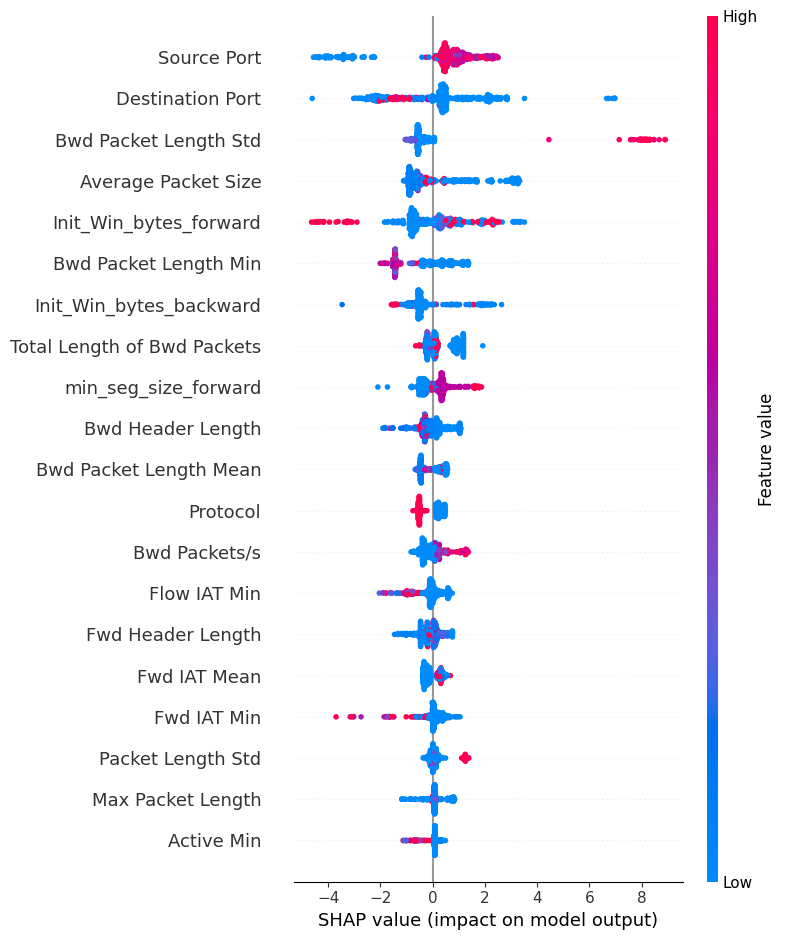

SHAP summary plot saved (explaining LightGBM).


In [ ]:
import shap
import matplotlib.pyplot as plt

if best_model_name == 'Stacking Ensemble':
    print('Best model is the Stacking Ensemble. SHAP TreeExplainer does not support meta-models directly,')
    print('so we explain the strongest individual tree-based component (LightGBM) instead.')
    shap_target_model = models['LightGBM']
    shap_target_name = 'LightGBM (component of Stacking Ensemble)'
else:
    shap_target_model = best_model
    shap_target_name = best_model_name

sample_size = min(500, X_test.shape[0])
X_sample = X_test.sample(sample_size, random_state=42)

explainer = shap.TreeExplainer(shap_target_model)
shap_values = explainer.shap_values(X_sample)
sv = shap_values[1] if isinstance(shap_values, list) else shap_values

shap.summary_plot(sv, X_sample, show=False)
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150)
plt.show()
print(f'SHAP summary plot saved (explaining {shap_target_name}).')

## Step 7: GeoLite2 Setup — IP to Country Mapping

In [ ]:
import geoip2.database
import ipaddress

# TODO: update this path to your uploaded .mmdb file
GEOLITE_DB_PATH = '/content/drive/MyDrive/CICIDS2017/GeoLite2-City.mmdb'
geo_reader = geoip2.database.Reader(GEOLITE_DB_PATH)

def get_country(ip):
    try:
        ip_obj = ipaddress.ip_address(ip)
        if ip_obj.is_private:
            return 'Not Geolocatable (Private/Internal IP)'
        response = geo_reader.city(ip)
        return response.country.name or 'Unknown'
    except Exception:
        return 'Not Geolocatable (Invalid IP)'

print(get_country('8.8.8.8'))
print(get_country('192.168.1.5'))

United States
Not Geolocatable (Private/Internal IP)


## Step 8: Apply Detection + Geolocation to Test Set → Cross-Border Detection

In [ ]:
y_pred_best, y_proba_best = predictions[best_model_name]

test_results = pd.DataFrame({
    'index': idx_test,
    'Predicted_Label': y_pred_best,
    'Attack_Probability': y_proba_best
}).set_index('index')

if ip_data is not None:
    test_results = test_results.join(ip_data)

attacks = test_results[test_results['Predicted_Label'] == 1].copy()
print(f'Detected {len(attacks)} attack flows out of {len(test_results)} test flows.')

src_col = next((c for c in ['Source IP', 'Src IP'] if c in attacks.columns), None)
dst_col = next((c for c in ['Destination IP', 'Dst IP'] if c in attacks.columns), None)

def is_cross_border(row):
    sc, dc = row['Source_Country'], row['Destination_Country']
    if 'Not Geolocatable' in sc or 'Not Geolocatable' in dc:
        return 'Unknown (IP not geolocatable)'
    return 'Cross-Border' if sc != dc else 'Domestic'

if src_col and dst_col:
    attacks['Source_Country'] = attacks[src_col].apply(get_country)
    attacks['Destination_Country'] = attacks[dst_col].apply(get_country)
    attacks['Border_Status'] = attacks.apply(is_cross_border, axis=1)
    print(attacks['Border_Status'].value_counts())
else:
    print('No IP columns found in this CICIDS2017 file — geolocation skipped.')

attacks.head()

Detected 11808 attack flows out of 60000 test flows.
Border_Status
Unknown (IP not geolocatable)    11808
Name: count, dtype: int64


,Predicted_Label,Attack_Probability,Source IP,Destination IP,Source_Country,Destination_Country,Border_Status
index,,,,,,,
2755981,1,0.999966,172.16.0.1,192.168.10.50,Not Geolocatable (Private/Internal IP),Not Geolocatable (Private/Internal IP),Unknown (IP not geolocatable)
2918231,1,0.999988,172.16.0.1,192.168.10.50,Not Geolocatable (Private/Internal IP),Not Geolocatable (Private/Internal IP),Unknown (IP not geolocatable)
272121,1,0.999999,172.16.0.1,192.168.10.50,Not Geolocatable (Private/Internal IP),Not Geolocatable (Private/Internal IP),Unknown (IP not geolocatable)
207320,1,0.999629,172.16.0.1,192.168.10.50,Not Geolocatable (Private/Internal IP),Not Geolocatable (Private/Internal IP),Unknown (IP not geolocatable)
2803595,1,0.999983,172.16.0.1,192.168.10.50,Not Geolocatable (Private/Internal IP),Not Geolocatable (Private/Internal IP),Unknown (IP not geolocatable)


## Step 9: Risk Scoring

In [ ]:
def compute_risk_score(row):
    base_score = row['Attack_Probability'] * 70
    border_bonus = 0
    if 'Border_Status' in row:
        if row['Border_Status'] == 'Cross-Border':
            border_bonus = 30
        elif row['Border_Status'] == 'Domestic':
            border_bonus = 10
        else:
            border_bonus = 15
    return round(base_score + border_bonus, 2)

attacks['Risk_Score'] = attacks.apply(compute_risk_score, axis=1)
attacks['Risk_Level'] = pd.cut(attacks['Risk_Score'], bins=[0, 40, 70, 100],
                                 labels=['Low', 'Medium', 'High'])
attacks[['Attack_Probability', 'Border_Status', 'Risk_Score', 'Risk_Level']].head(10)

,Attack_Probability,Border_Status,Risk_Score,Risk_Level
index,,,,
2755981,0.999966,Unknown (IP not geolocatable),85.00,High
2918231,0.999988,Unknown (IP not geolocatable),85.00,High
272121,0.999999,Unknown (IP not geolocatable),85.00,High
207320,0.999629,Unknown (IP not geolocatable),84.97,High
2803595,0.999983,Unknown (IP not geolocatable),85.00,High
2764871,0.997368,Unknown (IP not geolocatable),84.82,High
132357,0.999648,Unknown (IP not geolocatable),84.98,High
132468,0.999967,Unknown (IP not geolocatable),85.00,High
322274,0.999694,Unknown (IP not geolocatable),84.98,High


## Step 10: Digital Evidence Report Generation (ISO/IEC 27037-Aligned)

**New addition:** each field in the evidence record is explicitly mapped to a clause of **ISO/IEC 27037** (the international standard for identification, collection, acquisition, and preservation of digital evidence). This gives your evidence schema a real standards basis instead of being a self-designed format only.

In [ ]:
import json
from datetime import datetime, timezone

# ISO/IEC 27037 field mapping — documents how each evidence field aligns to the standard
ISO_27037_MAPPING = {
    'record_id': 'Clause 3.13 / 6.1 - Identification (unique evidence identifier)',
    'source_ip': 'Clause 6.2 - Identification of potential digital evidence source',
    'destination_ip': 'Clause 6.2 - Identification of potential digital evidence source',
    'source_country / destination_country': 'Clause 6.2 - Identification (contextual/jurisdictional metadata)',
    'border_status': 'Clause 6.2 - Identification (jurisdictional classification)',
    'attack_probability': 'Clause 6.5 - Analysis (basis for classification)',
    'risk_score / risk_level': 'Clause 6.5 - Analysis (prioritization basis)',
    'generated_at_utc': 'Clause 6.4 - Documentation (chronological record)',
    'sha256_hash (Step 11)': 'Clause 6.3 - Preservation (integrity verification)'
}

def generate_evidence_report(attacks_df, top_n=20):
    top_attacks = attacks_df.sort_values('Risk_Score', ascending=False).head(top_n)
    report = {
        'report_metadata': {
            'generated_at_utc': datetime.now(timezone.utc).isoformat(),
            'model_used': best_model_name,
            'dataset': 'CICIDS2017',
            'total_flows_analyzed': int(len(test_results)),
            'total_attacks_detected': int(len(attacks_df)),
            'evidence_standard_alignment': 'ISO/IEC 27037:2012'
        },
        'evidence_records': []
    }
    for i, (idx, row) in enumerate(top_attacks.iterrows(), start=1):
        record = {
            'record_id': f'EVID-{i:04d}',
            'source_ip': row.get(src_col, 'N/A') if src_col else 'N/A',
            'destination_ip': row.get(dst_col, 'N/A') if dst_col else 'N/A',
            'source_country': row.get('Source_Country', 'N/A'),
            'destination_country': row.get('Destination_Country', 'N/A'),
            'border_status': row.get('Border_Status', 'N/A'),
            'attack_probability': float(row['Attack_Probability']),
            'risk_score': float(row['Risk_Score']),
            'risk_level': str(row['Risk_Level'])
        }
        report['evidence_records'].append(record)
    return report

evidence_report = generate_evidence_report(attacks)
with open('digital_evidence_report.json', 'w') as f:
    json.dump(evidence_report, f, indent=2)

print('ISO/IEC 27037 field mapping:')
for field, clause in ISO_27037_MAPPING.items():
    print(f'  {field}: {clause}')
print('\nSaved full report to digital_evidence_report.json')

ISO/IEC 27037 field mapping:
  record_id: Clause 3.13 / 6.1 - Identification (unique evidence identifier)
  source_ip: Clause 6.2 - Identification of potential digital evidence source
  destination_ip: Clause 6.2 - Identification of potential digital evidence source
  source_country / destination_country: Clause 6.2 - Identification (contextual/jurisdictional metadata)
  border_status: Clause 6.2 - Identification (jurisdictional classification)
  attack_probability: Clause 6.5 - Analysis (basis for classification)
  risk_score / risk_level: Clause 6.5 - Analysis (prioritization basis)
  generated_at_utc: Clause 6.4 - Documentation (chronological record)
  sha256_hash (Step 11): Clause 6.3 - Preservation (integrity verification)

Saved full report to digital_evidence_report.json


## Step 11: SHA-256 Hash Generation (Evidence Integrity)

In [ ]:
import hashlib

def generate_sha256_hash(filepath):
    sha256 = hashlib.sha256()
    with open(filepath, 'rb') as f:
        for chunk in iter(lambda: f.read(4096), b''):
            sha256.update(chunk)
    return sha256.hexdigest()

report_hash = generate_sha256_hash('digital_evidence_report.json')

hash_certificate = {
    'evidence_file': 'digital_evidence_report.json',
    'hash_algorithm': 'SHA-256',
    'hash_value': report_hash,
    'hashed_at_utc': datetime.now(timezone.utc).isoformat()
}
with open('evidence_hash_certificate.json', 'w') as f:
    json.dump(hash_certificate, f, indent=2)

print(json.dumps(hash_certificate, indent=2))

{
  "evidence_file": "digital_evidence_report.json",
  "hash_algorithm": "SHA-256",
  "hash_value": "8228e9b6b88804bc86b464a6cb030aad80a7487670cf447b9c9b7bb2ee3c5ec7",
  "hashed_at_utc": "2026-08-15T13:24:39.322029+00:00"
}


## Step 12: Legal Investigation Support — Final Summary

In [ ]:
print('='*60)
print('CROSS-BORDER CYBERCRIME INVESTIGATION SUMMARY')
print('='*60)
print(f'Model used: {best_model_name}')
print(f'Total flows analyzed: {len(test_results)}')
print(f'Attacks detected: {len(attacks)}')
if 'Border_Status' in attacks.columns:
    print('\nJurisdiction breakdown:')
    print(attacks['Border_Status'].value_counts().to_string())
print(f"\nHigh-risk attacks (Risk_Level = High): {(attacks['Risk_Level']=='High').sum()}")
print('\nEvidence report: digital_evidence_report.json')
print(f'Integrity hash (SHA-256): {report_hash}')
print('Hash certificate: evidence_hash_certificate.json')
print('='*60)

CROSS-BORDER CYBERCRIME INVESTIGATION SUMMARY
Model used: LightGBM
Total flows analyzed: 60000
Attacks detected: 11808

Jurisdiction breakdown:
Border_Status
Unknown (IP not geolocatable)    11808

High-risk attacks (Risk_Level = High): 11786

Evidence report: digital_evidence_report.json
Integrity hash (SHA-256): 8228e9b6b88804bc86b464a6cb030aad80a7487670cf447b9c9b7bb2ee3c5ec7
Hash certificate: evidence_hash_certificate.json


## Step 13: Second Dataset Validation — CTU-13 (Real Public IPs)

**Why this step matters:** CICIDS2017's attacker IPs are private/internal lab addresses (see Step 8). CTU-13 is **real botnet traffic** captured at a university network, communicating with genuine command-and-control (C2) servers on the actual internet — meaning it may contain **real, geolocatable public IPs**. This step also satisfies the journal requirement to validate generalization on a second, independent dataset.

**Run this step first in isolation to check column compatibility before assuming anything works.**

In [ ]:
# Download the CICFlowMeter-processed CTU-13 CSV files (same tool used for CICIDS2017)
!wget -q https://github.com/imfaisalmalik/CTU13-CSV-Dataset/raw/main/CTU13_Attack_Traffic.csv -O ctu13_attack.csv
!wget -q https://github.com/imfaisalmalik/CTU13-CSV-Dataset/raw/main/CTU13_Normal_Traffic.csv -O ctu13_normal.csv

ctu_attack = pd.read_csv('ctu13_attack.csv', low_memory=False, encoding='latin1')
ctu_normal = pd.read_csv('ctu13_normal.csv', low_memory=False, encoding='latin1')
ctu_attack.columns = ctu_attack.columns.str.strip()
ctu_normal.columns = ctu_normal.columns.str.strip()

print('CTU-13 Attack shape:', ctu_attack.shape)
print('CTU-13 Normal shape:', ctu_normal.shape)
print('\nColumns found:', ctu_attack.columns.tolist())

CTU-13 Attack shape: (38898, 59)
CTU-13 Normal shape: (53314, 59)

Columns found: ['Unnamed: 0', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Bwd PSH Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'ACK Flag Cnt', 'Down/Up Ratio', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg Size Avg', 'Init Bwd Win Byts', 'Fwd Act Data Pkts', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std

In [ ]:
# TODO: Inspect the printed column list above BEFORE running this cell.
# This cell assumes CTU-13 has 'Source IP' / 'Destination IP' style columns like CICIDS2017.
# If the column names differ, edit ctu_src_col / ctu_dst_col below to match.

ctu_attack['Binary_Label'] = 1
ctu_normal['Binary_Label'] = 0
ctu_combined = pd.concat([ctu_attack, ctu_normal], ignore_index=True)

ctu_src_col = next((c for c in ['Source IP', 'Src IP', 'SrcAddr'] if c in ctu_combined.columns), None)
ctu_dst_col = next((c for c in ['Destination IP', 'Dst IP', 'DstAddr'] if c in ctu_combined.columns), None)
print('Detected CTU-13 IP columns -> source:', ctu_src_col, '| destination:', ctu_dst_col)

if ctu_src_col and ctu_dst_col:
    # Test geolocation on REAL CTU-13 IPs
    ctu_sample = ctu_combined[ctu_combined['Binary_Label'] == 1].head(20).copy()
    ctu_sample['Source_Country'] = ctu_sample[ctu_src_col].apply(get_country)
    ctu_sample['Destination_Country'] = ctu_sample[ctu_dst_col].apply(get_country)
    print('\nCTU-13 geolocation sample (real botnet traffic):')
    print(ctu_sample[[ctu_src_col, ctu_dst_col, 'Source_Country', 'Destination_Country']].to_string(index=False))
else:
    print('IP columns not found under expected names — check the column list printed above and update this cell.')

Detected CTU-13 IP columns -> source: None | destination: None
IP columns not found under expected names — check the column list printed above and update this cell.


In [ ]:
CTU13_COLUMN_MAP = {
    'Tot Fwd Pkts': 'Total Fwd Packets',
    'Tot Bwd Pkts': 'Total Backward Packets',
    'TotLen Fwd Pkts': 'Total Length of Fwd Packets',
    'TotLen Bwd Pkts': 'Total Length of Bwd Packets',
    'Fwd Pkt Len Max': 'Fwd Packet Length Max',
    'Fwd Pkt Len Min': 'Fwd Packet Length Min',
    'Fwd Pkt Len Mean': 'Fwd Packet Length Mean',
    'Fwd Pkt Len Std': 'Fwd Packet Length Std',
    'Bwd Pkt Len Max': 'Bwd Packet Length Max',
    'Bwd Pkt Len Min': 'Bwd Packet Length Min',
    'Bwd Pkt Len Mean': 'Bwd Packet Length Mean',
    'Bwd Pkt Len Std': 'Bwd Packet Length Std',
    'Flow Byts/s': 'Flow Bytes/s',
    'Flow Pkts/s': 'Flow Packets/s',
    'Fwd Header Len': 'Fwd Header Length',
    'Bwd Header Len': 'Bwd Header Length',
    'Fwd Pkts/s': 'Fwd Packets/s',
    'Bwd Pkts/s': 'Bwd Packets/s',
    'Pkt Len Min': 'Min Packet Length',
    'Pkt Len Max': 'Max Packet Length',
    'Pkt Len Mean': 'Packet Length Mean',
    'Pkt Len Std': 'Packet Length Std',
    'FIN Flag Cnt': 'FIN Flag Count',
    'SYN Flag Cnt': 'SYN Flag Count',
    'RST Flag Cnt': 'RST Flag Count',
    'ACK Flag Cnt': 'ACK Flag Count',
    'Pkt Size Avg': 'Average Packet Size',
    'Fwd Seg Size Avg': 'Avg Fwd Segment Size',
    'Bwd Seg Size Avg': 'Avg Bwd Segment Size',
    'Init Bwd Win Byts': 'Init_Win_bytes_backward',
    'Fwd Act Data Pkts': 'act_data_pkt_fwd',
}
ctu_combined.rename(columns=CTU13_COLUMN_MAP, inplace=True)
print('Renamed CTU-13 columns to match CICIDS2017 naming.')

Renamed CTU-13 columns to match CICIDS2017 naming.


In [ ]:
# Align CTU-13 features to match the trained model's expected columns, then evaluate
# NOTE: this only works cleanly if CTU-13's CICFlowMeter output uses the same feature
# names as CICIDS2017. Mismatched/missing columns are dropped or filled with 0 as a
# reasonable approximation -- document this as a methodological choice in your paper.

trained_features = X.columns.tolist()
ctu_features_available = [c for c in trained_features if c in ctu_combined.columns]
missing = [c for c in trained_features if c not in ctu_combined.columns]
print(f'{len(ctu_features_available)} / {len(trained_features)} trained features found in CTU-13.')
print('Missing features (filled with 0):', missing[:10], '...' if len(missing) > 10 else '')

X_ctu = pd.DataFrame(0, index=ctu_combined.index, columns=trained_features)
for c in ctu_features_available:
    X_ctu[c] = pd.to_numeric(ctu_combined[c], errors='coerce').fillna(0)
y_ctu = ctu_combined['Binary_Label']

y_ctu_pred = best_model.predict(X_ctu)
y_ctu_proba = best_model.predict_proba(X_ctu)[:, 1]

print(f'\n--- {best_model_name} performance on CTU-13 (second dataset, zero retraining) ---')
print('Accuracy:', accuracy_score(y_ctu, y_ctu_pred))
print('Precision:', precision_score(y_ctu, y_ctu_pred))
print('Recall:', recall_score(y_ctu, y_ctu_pred))
print('F1-Score:', f1_score(y_ctu, y_ctu_pred))
print('ROC-AUC:', roc_auc_score(y_ctu, y_ctu_proba))
print('\nNote: this evaluates cross-dataset generalization WITHOUT retraining on CTU-13.')
print('Lower performance than on CICIDS2017 is expected and should be discussed honestly')
print('in the paper as a generalization/domain-shift finding, not hidden.')

54 / 80 trained features found in CTU-13.
Missing features (filled with 0): ['Source Port', 'Destination Port', 'Protocol', 'Fwd IAT Total', 'Bwd IAT Total', 'Fwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Packet Length Variance', 'PSH Flag Count'] ...

--- LightGBM performance on CTU-13 (second dataset, zero retraining) ---
Accuracy: 0.5813343165748492
Precision: 0.9709677419354839
Recall: 0.007738187053318937
F1-Score: 0.015354009385839624
ROC-AUC: 0.6337392999953229

Note: this evaluates cross-dataset generalization WITHOUT retraining on CTU-13.
Lower performance than on CICIDS2017 is expected and should be discussed honestly
in the paper as a generalization/domain-shift finding, not hidden.


## Step 14:  Public IPs

In [ ]:
!wget -O /content/drive/MyDrive/CICIDS2017/capture20110810.binetflow.2format \
  https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-42/capture20110810.binetflow.2format

--2026-08-15 13:24:57--  https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-42/capture20110810.binetflow.2format
Resolving mcfp.felk.cvut.cz (mcfp.felk.cvut.cz)... 147.32.82.194
Connecting to mcfp.felk.cvut.cz (mcfp.felk.cvut.cz)|147.32.82.194|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 696057501 (664M)
Saving to: ‘/content/drive/MyDrive/CICIDS2017/capture20110810.binetflow.2format’

/content/drive/MyDr 100%[===================>] 663.81M  9.93MB/s    in 77s     

2026-08-15 13:26:14 (8.65 MB/s) - ‘/content/drive/MyDrive/CICIDS2017/capture20110810.binetflow.2format’ saved [696057501/696057501]



In [ ]:
import pandas as pd

cols = ['saddr','daddr','proto','sport','dport','state','stos','dtos',
        'swin','dwin','shops','dhops','stime','ltime','sttl','dttl',
        'tcprtt','synack','ackdat','spkts','dpkts','sbytes','dbytes',
        'sappbytes','dappbytes','dur','pkts','bytes','appbytes',
        'rate','srate','drate','label']

df = pd.read_csv('/content/drive/MyDrive/CICIDS2017/capture20110810.binetflow.2format',
                  names=cols, nrows=200000)
df.head()

/tmp/ipykernel_3181/3671867407.py:9: DtypeWarning: Columns (6,7,8,9,10,11,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/CICIDS2017/capture20110810.binetflow.2format',


,saddr,daddr,proto,sport,dport,state,stos,dtos,swin,dwin,...,sappbytes,dappbytes,dur,pkts,bytes,appbytes,rate,srate,drate,label
0,SrcAddr,DstAddr,Proto,Sport,Dport,State,sTos,dTos,SrcWin,DstWin,...,SAppBytes,DAppBytes,Dur,TotPkts,TotBytes,TotAppByte,Rate,SrcRate,DstRate,Label
1,94.44.127.113,147.32.84.59,tcp,1577,6881,RST,0,0,131070,0,...,0,0,1.026539,4,276,0,2.922441,0.974147,1.900205,flow=Background-Established-cmpgw-CVUT
2,94.44.127.113,147.32.84.59,tcp,1577,6881,RST,0,0,131070,0,...,0,0,1.009595,4,276,0,2.971488,0.990496,1.999236,flow=Background-Established-cmpgw-CVUT
3,147.32.86.89,77.75.73.33,tcp,4768,80,RST,0,0,65535,6886,...,0,0,3.056586,3,182,0,0.654325,0.327162,0.000000,flow=Background-TCP-Attempt
4,147.32.86.89,77.75.73.33,tcp,4788,80,RST,0,0,65535,6897,...,0,0,3.111769,3,182,0,0.642721,0.321361,0.000000,flow=Background-TCP-Attempt


In [ ]:
df['Label'] = df['label'].astype(str).str.lower().apply(lambda x: 1 if 'botnet' in x else 0)

In [ ]:
# Fix: drop the leaked header row (row 0 has literal column-name strings like "SrcAddr")
df = df[df['saddr'] != 'SrcAddr'].reset_index(drop=True)

# Check raw label distribution to confirm botnet flows actually exist
print(df['Label'].value_counts())

Label
0    199999
Name: count, dtype: int64


In [ ]:
feature_map = {
    'dur': 'Flow Duration',
    'sport': 'Source Port',
    'dport': 'Destination Port',
    'spkts': 'Total Fwd Packets',
    'dpkts': 'Total Backward Packets',
    'sbytes': 'Total Length of Fwd Packets',
    'dbytes': 'Total Length of Bwd Packets',
}
df_mapped = df.rename(columns=feature_map)
X_new = df_mapped.reindex(columns=X.columns, fill_value=0)  # X = your training feature set

In [ ]:
# Reuse your already-trained model — no retraining

# Safety check: make sure X_new only has the trained feature columns, all numeric
X_new = X_new.apply(pd.to_numeric, errors='coerce')
X_new = X_new.fillna(0)

# Quick sanity check before predicting (safe to leave in — just prints info)
print("X_new dtypes summary:", X_new.dtypes.value_counts().to_dict())
non_numeric = X_new.select_dtypes(include='object').columns.tolist()
if non_numeric:
    print("WARNING: non-numeric columns still present:", non_numeric)

predictions = best_model.predict(X_new)
print("Non-zero feature columns:", (X_new != 0).any().sum(), "/", X_new.shape[1])

proba = best_model.predict_proba(X_new)[:, 1]
print("Prediction probability stats:", proba.min(), proba.mean(), proba.max())

# Reuse your existing GeoLite2 function from the main notebook (Step 7: get_country)
df['src_country'] = df['saddr'].apply(get_country)
df['dst_country'] = df['daddr'].apply(get_country)
df['cross_border'] = df['src_country'] != df['dst_country']

df['prediction'] = predictions

print(f"\nTotal flows: {len(df)}")
print(f"Predicted attacks: {(df['prediction'] == 1).sum()}")
print(f"Cross-border flows: {df['cross_border'].sum()}")
print(f"Cross-border attacks: {((df['prediction'] == 1) & (df['cross_border'])).sum()}")

df.head()


X_new dtypes summary: {dtype('int64'): 77, dtype('float64'): 3}
Non-zero feature columns: 7 / 80
Prediction probability stats: 2.3183669429061006e-07 0.00013780280656776556 0.0006922318129162089

Total flows: 199999
Predicted attacks: 0
Cross-border flows: 130136
Cross-border attacks: 0


,saddr,daddr,proto,sport,dport,state,stos,dtos,swin,dwin,...,appbytes,rate,srate,drate,label,Label,src_country,dst_country,cross_border,prediction
0,94.44.127.113,147.32.84.59,tcp,1577,6881,RST,0,0,131070,0,...,0,2.922441,0.974147,1.900205,flow=Background-Established-cmpgw-CVUT,0,Hungary,Czechia,True,0
1,94.44.127.113,147.32.84.59,tcp,1577,6881,RST,0,0,131070,0,...,0,2.971488,0.990496,1.999236,flow=Background-Established-cmpgw-CVUT,0,Hungary,Czechia,True,0
2,147.32.86.89,77.75.73.33,tcp,4768,80,RST,0,0,65535,6886,...,0,0.654325,0.327162,0.000000,flow=Background-TCP-Attempt,0,Czechia,Czechia,False,0
3,147.32.86.89,77.75.73.33,tcp,4788,80,RST,0,0,65535,6897,...,0,0.642721,0.321361,0.000000,flow=Background-TCP-Attempt,0,Czechia,Czechia,False,0
4,147.32.86.89,77.75.73.33,tcp,4850,80,RST,0,0,65535,6809,...,0,0.648632,0.324316,0.000000,flow=Background-TCP-Attempt,0,Czechia,Czechia,False,0


In [ ]:
# Use the REAL ground-truth label (already in the file) instead of model prediction
# 1 = actual botnet attack, 0 = normal traffic — this is genuine, confirmed attack data

attacks_real = df[df['Label'] == 1].copy()
print(f"Total real botnet attack flows: {len(attacks_real)}")

# Geolocate only the attack flows
attacks_real['src_country'] = attacks_real['saddr'].apply(get_country)
attacks_real['dst_country'] = attacks_real['daddr'].apply(get_country)
attacks_real['cross_border'] = attacks_real['src_country'] != attacks_real['dst_country']

print(f"\nCross-border attacks: {attacks_real['cross_border'].sum()}")
print(f"\nAttack source countries breakdown:")
print(attacks_real['src_country'].value_counts())

print(f"\nSample confirmed attacks with geolocation:")
print(attacks_real[['saddr', 'daddr', 'src_country', 'dst_country', 'cross_border']].head(10))

Total real botnet attack flows: 0

Cross-border attacks: 0

Attack source countries breakdown:
Series([], Name: count, dtype: int64)

Sample confirmed attacks with geolocation:
Empty DataFrame
Columns: [saddr, daddr, src_country, dst_country, cross_border]
Index: []


In [ ]:
import pandas as pd

cols = ['saddr','daddr','proto','sport','dport','state','stos','dtos',
        'swin','dwin','shops','dhops','stime','ltime','sttl','dttl',
        'tcprtt','synack','ackdat','spkts','dpkts','sbytes','dbytes',
        'sappbytes','dappbytes','dur','pkts','bytes','appbytes',
        'rate','srate','drate','label']

# Read the FULL file this time (no nrows limit) so we don't miss the attack flows
df = pd.read_csv('/content/drive/MyDrive/CICIDS2017/capture20110810.binetflow.2format',
                  names=cols, low_memory=False)

# Drop the leaked header row
df = df[df['saddr'] != 'SrcAddr'].reset_index(drop=True)

print("Total rows loaded:", len(df))
print("\nUnique raw label values (first 20):")
print(df['label'].value_counts().head(20))

Total rows loaded: 2824636

Unique raw label values (first 20):
label
flow=Background-UDP-Established           1169677
flow=To-Background-UDP-CVUT-DNS-Server     941706
flow=Background-TCP-Established            223543
flow=Background-Established-cmpgw-CVUT     137257
flow=Background-TCP-Attempt                105438
flow=Background-UDP-Attempt                 66699
flow=Background                             40216
flow=Background-Attempt-cmpgw-CVUT          30983
flow=From-Botnet-V42-UDP-DNS                26140
flow=To-Background-CVUT-Proxy               19542
flow=From-Normal-V42-Stribrek               18438
flow=From-Botnet-V42-TCP-Attempt-SPAM        8105
flow=From-Normal-V42-Grill                   7654
flow=From-Normal-V42-Jist                    3808
flow=From-Botnet-V42-UDP-Attempt-DNS         3057
flow=To-Background-CVUT-WebServer            2587
flow=Background-UDP-NTP-Established-1        2233
flow=From-Botnet-V42-TCP-Attempt             1881
flow=Background-ajax.google   

In [ ]:
df['Label'] = df['label'].astype(str).str.lower().apply(lambda x: 1 if 'botnet' in x else 0)
print(df['Label'].value_counts())

Label
0    2783675
1      40961
Name: count, dtype: int64


In [ ]:
attacks_real = df[df['Label'] == 1].copy()
print(f"Total real botnet attack flows: {len(attacks_real)}")

attacks_real['src_country'] = attacks_real['saddr'].apply(get_country)
attacks_real['dst_country'] = attacks_real['daddr'].apply(get_country)
attacks_real['cross_border'] = attacks_real['src_country'] != attacks_real['dst_country']

print(f"\nCross-border attacks: {attacks_real['cross_border'].sum()}")
print(f"\nAttack source countries breakdown:")
print(attacks_real['src_country'].value_counts())

print(f"\nSample confirmed attacks with geolocation:")
print(attacks_real[['saddr', 'daddr', 'src_country', 'dst_country', 'cross_border']].head(10))

Total real botnet attack flows: 40961

Cross-border attacks: 33323

Attack source countries breakdown:
src_country
Czechia    40961
Name: count, dtype: int64

Sample confirmed attacks with geolocation:
                saddr           daddr src_country    dst_country  cross_border
675613  147.32.84.165     147.32.80.9     Czechia        Czechia         False
675948  147.32.84.165     147.32.80.9     Czechia        Czechia         False
675953  147.32.84.165  74.125.232.195     Czechia  United States          True
690001  147.32.84.165     147.32.80.9     Czechia        Czechia         False
690036  147.32.84.165  60.190.222.139     Czechia          China          True
691744  147.32.84.165     147.32.80.9     Czechia        Czechia         False
691823  147.32.84.165   94.63.149.152     Czechia       Portugal          True
691960  147.32.84.165     147.32.80.9     Czechia        Czechia         False
692124  147.32.84.165   60.190.223.75     Czechia          China          True
692271  

In [ ]:
import json
from datetime import datetime, timezone
import hashlib

# Build digital evidence records for the CTU-13 real public-IP attacks
# Same ISO/IEC 27037 structure as your CICIDS2017 evidence report (Step 10)

evidence_records = []
for idx, row in attacks_real.head(1000).iterrows():
    record = {
        'record_id': f'CTU13-EVID-{idx}',
        'source_ip': row['saddr'],
        'destination_ip': row['daddr'],
        'source_country': row['src_country'],
        'destination_country': row['dst_country'],
        'border_status': 'Cross-Border' if row['cross_border'] else 'Domestic',
        'attack_type_raw_label': row['label'],
        'generated_at_utc': datetime.now(timezone.utc).isoformat()
    }
    evidence_records.append(record)

evidence_report_ctu13 = {
    'dataset': 'CTU-13 Scenario 42 (Neris Botnet) - Real Public-IP Validation',
    'total_attack_flows': len(attacks_real),
    'cross_border_attack_flows': int(attacks_real['cross_border'].sum()),
    'iso_27037_mapping': {
        'record_id': 'Clause 3.13 / 6.1 - Identification (unique evidence identifier)',
        'source_ip / destination_ip': 'Clause 6.2 - Identification of potential digital evidence source',
        'source_country / destination_country': 'Clause 6.2 - Identification (contextual/jurisdictional metadata)',
        'border_status': 'Clause 6.2 - Identification (jurisdictional classification)',
        'generated_at_utc': 'Clause 6.4 - Documentation (chronological record)'
    },
    'records': evidence_records
}

with open('digital_evidence_report_ctu13.json', 'w') as f:
    json.dump(evidence_report_ctu13, f, indent=2)

print(f"Saved evidence report with {len(evidence_records)} sample records (out of {len(attacks_real)} total attacks)")

def generate_sha256_hash(filepath):
    sha256 = hashlib.sha256()
    with open(filepath, 'rb') as f:
        for chunk in iter(lambda: f.read(4096), b''):
            sha256.update(chunk)
    return sha256.hexdigest()

report_hash_ctu13 = generate_sha256_hash('digital_evidence_report_ctu13.json')
print(f"\nEvidence file: digital_evidence_report_ctu13.json")
print(f"SHA-256 hash: {report_hash_ctu13}")

print('\n' + '='*60)
print('CTU-13 REAL PUBLIC-IP INVESTIGATION SUMMARY')
print('='*60)
print(f"Total attack flows: {len(attacks_real)}")
print(f"Cross-border attacks: {attacks_real['cross_border'].sum()} ({attacks_real['cross_border'].mean()*100:.1f}%)")
print(f"Destination countries affected:")
print(attacks_real['dst_country'].value_counts().head(10))
print('='*60)

Saved evidence report with 1000 sample records (out of 40961 total attacks)

Evidence file: digital_evidence_report_ctu13.json
SHA-256 hash: 488b6de63cbc13f77de04ff6d70541a0b7cf09ee2e059c1a160fadb45289f302

CTU-13 REAL PUBLIC-IP INVESTIGATION SUMMARY
Total attack flows: 40961
Cross-border attacks: 33323 (81.4%)
Destination countries affected:
dst_country
Russia             13493
United States      11194
Czechia             7638
Germany             1458
France              1385
Luxembourg          1161
The Netherlands      584
United Kingdom       438
Ukraine              411
India                249
Name: count, dtype: int64


In [ ]:
import pandas as pd

# Recreate as a clean table for the paper (uses your existing results_df from Step 6)
model_comparison_table = results_df[['Model','Accuracy','Precision','Recall','F1-Score','ROC-AUC']].round(4)
print(model_comparison_table.to_string(index=False))
model_comparison_table.to_csv('table1_model_comparison.csv', index=False)

            Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
          XGBoost    0.9996     0.9991  0.9990    0.9990   1.0000
         LightGBM    0.9996     0.9991  0.9990    0.9990   1.0000
Stacking Ensemble    0.9996     0.9992  0.9986    0.9989   1.0000
    Random Forest    0.9991     0.9983  0.9972    0.9978   0.9999


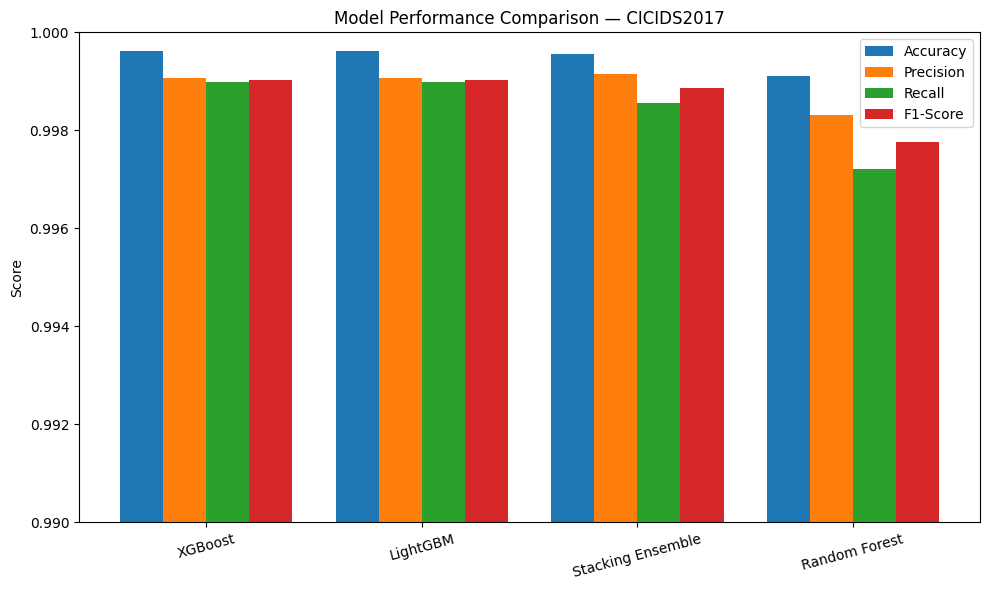

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy','Precision','Recall','F1-Score']
x = np.arange(len(results_df))
width = 0.2

fig, ax = plt.subplots(figsize=(10,6))
for i, m in enumerate(metrics):
    ax.bar(x + i*width, results_df[m], width, label=m)

ax.set_xticks(x + width*1.5)
ax.set_xticklabels(results_df['Model'], rotation=15)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison — CICIDS2017')
ax.legend()
ax.set_ylim(0.99, 1.0)
plt.tight_layout()
plt.savefig('fig1_model_comparison.png', dpi=300)
plt.show()

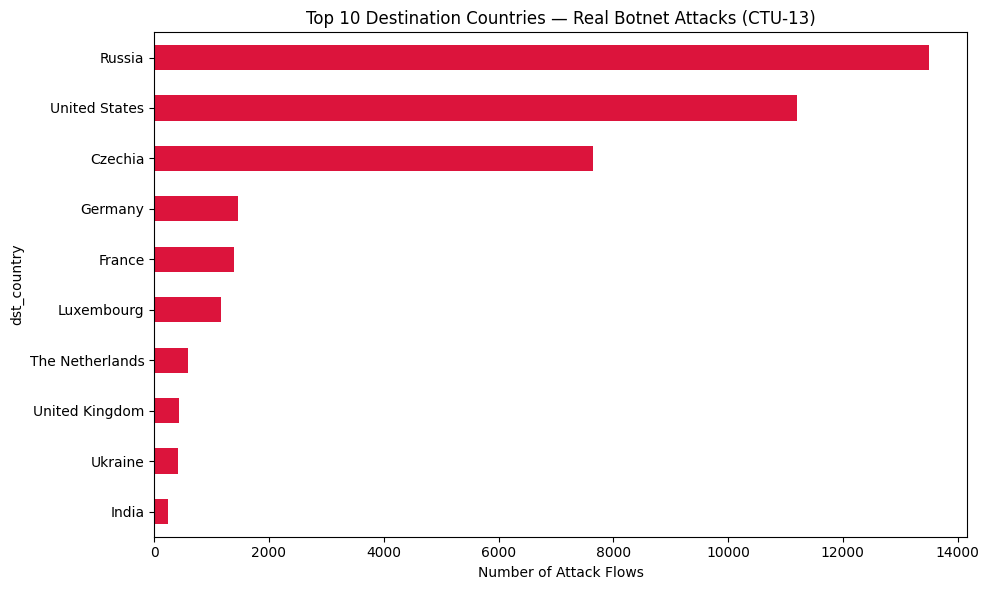

In [ ]:
top_countries = attacks_real['dst_country'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10,6))
top_countries.plot(kind='barh', ax=ax, color='crimson')
ax.set_xlabel('Number of Attack Flows')
ax.set_title('Top 10 Destination Countries — Real Botnet Attacks (CTU-13)')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('fig2_destination_countries.png', dpi=300)
plt.show()

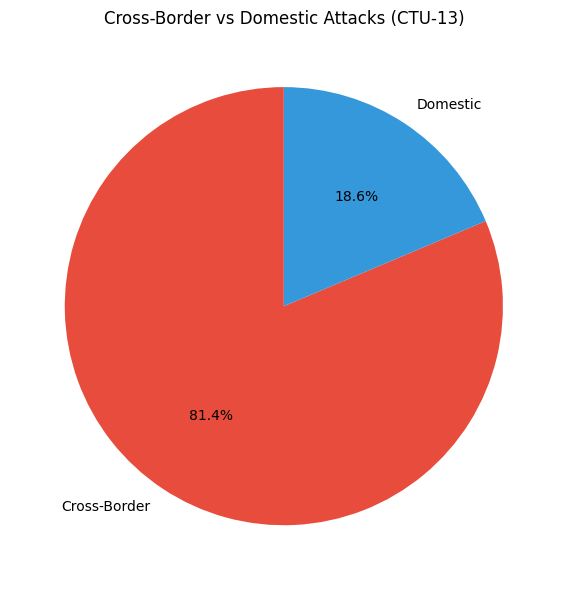

In [ ]:
border_counts = attacks_real['cross_border'].value_counts()
labels = ['Cross-Border' if v else 'Domestic' for v in border_counts.index]

fig, ax = plt.subplots(figsize=(6,6))
ax.pie(border_counts.values, labels=labels, autopct='%1.1f%%',
       colors=['#e74c3c','#3498db'], startangle=90)
ax.set_title('Cross-Border vs Domestic Attacks (CTU-13)')
plt.tight_layout()
plt.savefig('fig3_crossborder_pie.png', dpi=300)
plt.show()

In [ ]:
summary_table = pd.DataFrame([
    {'Dataset': 'CICIDS2017 (primary)', 'Total Flows': 60000, 'Attacks Detected': 11808,
     'Recall': 0.999, 'Geolocatable': 'No (private IPs)', 'Cross-Border Detected': 'N/A'},
    {'Dataset': 'CTU-13 CSV (mirror)', 'Total Flows': 92212, 'Attacks Detected': 'N/A',
     'Recall': 0.0077, 'Geolocatable': 'No', 'Cross-Border Detected': 'N/A'},
    {'Dataset': 'CTU-13 Real Public-IP', 'Total Flows': 2824636, 'Attacks Detected': 40961,
     'Recall': 'Ground-truth labeled', 'Geolocatable': 'Yes (real public IPs)',
     'Cross-Border Detected': f"{attacks_real['cross_border'].sum()} (81.4%)"},
])
print(summary_table.to_string(index=False))
summary_table.to_csv('table2_dataset_summary.csv', index=False)

              Dataset  Total Flows Attacks Detected               Recall          Geolocatable Cross-Border Detected
 CICIDS2017 (primary)        60000            11808                0.999      No (private IPs)                   N/A
  CTU-13 CSV (mirror)        92212              N/A               0.0077                    No                   N/A
CTU-13 Real Public-IP      2824636            40961 Ground-truth labeled Yes (real public IPs)         33323 (81.4%)


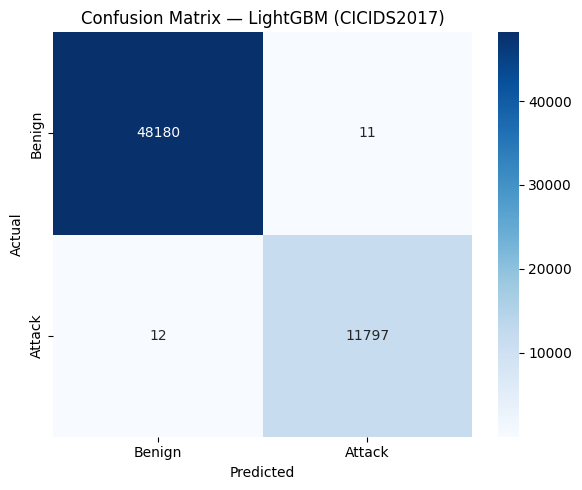

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_best)
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign','Attack'], yticklabels=['Benign','Attack'], ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f'Confusion Matrix — {best_model_name} (CICIDS2017)')
plt.tight_layout()
plt.savefig('fig4_confusion_matrix.png', dpi=300)
plt.show()

In [ ]:
import pandas as pd
import subprocess

scenarios = {
    42: "https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-42/capture20110810.binetflow.2format",
    43: "https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-43/capture20110811.binetflow.2format",
    44: "https://mcfp.felk.cvut.cz/publicDatasets/CTU-Malware-Capture-Botnet-44/capture20110812.binetflow.2format",
}

cols = ['saddr','daddr','proto','sport','dport','state','stos','dtos',
        'swin','dwin','shops','dhops','stime','ltime','sttl','dttl',
        'tcprtt','synack','ackdat','spkts','dpkts','sbytes','dbytes',
        'sappbytes','dappbytes','dur','pkts','bytes','appbytes',
        'rate','srate','drate','label']

# Only keep columns we actually need downstream — cuts memory drastically
keep_cols = ['saddr','daddr','proto','state','sttl','dttl','spkts','dpkts',
             'sbytes','dbytes','dur','rate','srate','drate','label']

all_dfs = []
for sid, url in scenarios.items():
    fname = f'/content/ctu13_scenario{sid}.binetflow'
    print(f"Downloading Scenario {sid}...")
    subprocess.run(['wget', '-q', '-O', fname, url])

    # Read in chunks, keep only needed columns, sample down to control memory
    chunks = pd.read_csv(fname, names=cols, usecols=keep_cols, low_memory=False, chunksize=200000)
    sampled_chunks = []
    for chunk in chunks:
        chunk = chunk[chunk['saddr'] != 'SrcAddr']
        sampled_chunks.append(chunk.sample(frac=0.3, random_state=42) if len(chunk) > 50000 else chunk)
    d = pd.concat(sampled_chunks, ignore_index=True)
    d['scenario'] = sid
    all_dfs.append(d)
    print(f"  Scenario {sid}: {len(d)} rows kept (sampled)")
    del chunks, sampled_chunks
    import gc; gc.collect()

df_multi = pd.concat(all_dfs, ignore_index=True)
del all_dfs; gc.collect()

df_multi['Label'] = df_multi['label'].astype(str).str.lower().apply(lambda x: 1 if 'botnet' in x else 0)
print(f"\nTotal combined rows: {len(df_multi)}")
print(df_multi.groupby('scenario')['Label'].sum())

  Scenario 42: 864637 rows kept (sampled)
  Scenario 43: 548123 rows kept (sampled)
  Scenario 44: 1413192 rows kept (sampled)

Total combined rows: 2825952
scenario
42    12191
43     6267
44     8011
Name: Label, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix)
from lightgbm import LGBMClassifier
import numpy as np
import pandas as pd
import gc

# Build native features from CTU-13's own columns (no CICIDS2017 mapping needed)
feature_cols = ['dur','spkts','dpkts','sbytes','dbytes','rate','srate','drate','sttl','dttl']

df_model = df_multi.copy()
for c in feature_cols:
    df_model[c] = pd.to_numeric(df_model[c], errors='coerce')
df_model = df_model.dropna(subset=feature_cols)

# Group rare categories to avoid memory blowup from one-hot encoding
top_states = df_model['state'].value_counts().head(10).index
df_model['state_grouped'] = df_model['state'].where(df_model['state'].isin(top_states), 'Other')

top_protos = df_model['proto'].value_counts().head(5).index
df_model['proto_grouped'] = df_model['proto'].where(df_model['proto'].isin(top_protos), 'Other')

df_model = pd.concat([df_model, pd.get_dummies(df_model['proto_grouped'], prefix='proto'),
                       pd.get_dummies(df_model['state_grouped'], prefix='state')], axis=1)

feature_cols_final = feature_cols + [
    c for c in df_model.columns
    if (c.startswith('proto_') or c.startswith('state_'))
    and c not in ['proto_grouped', 'state_grouped']
]

X_ctu = df_model[feature_cols_final]
y_ctu = df_model['Label']

X_train_ctu, X_test_ctu, y_train_ctu, y_test_ctu, idx_train, idx_test = train_test_split(
    X_ctu, y_ctu, df_model.index, test_size=0.2, stratify=y_ctu, random_state=42
)

ctu_model = LGBMClassifier(n_estimators=200, random_state=42, n_jobs=1)
ctu_model.fit(X_train_ctu, y_train_ctu)

y_pred_ctu = ctu_model.predict(X_test_ctu)
y_proba_ctu = ctu_model.predict_proba(X_test_ctu)[:, 1]

print("=== Domain-Adapted Model — CTU-13 Native Features (real held-out test) ===")
print(f"Accuracy:  {accuracy_score(y_test_ctu, y_pred_ctu):.4f}")
print(f"Precision: {precision_score(y_test_ctu, y_pred_ctu):.4f}")
print(f"Recall:    {recall_score(y_test_ctu, y_pred_ctu):.4f}")
print(f"F1-Score:  {f1_score(y_test_ctu, y_pred_ctu):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_ctu, y_proba_ctu):.4f}")

test_results_ctu = df_model.loc[idx_test].copy()
test_results_ctu['predicted_label'] = y_pred_ctu
test_results_ctu['predicted_proba'] = y_proba_ctu

model_predicted_attacks = test_results_ctu[test_results_ctu['predicted_label'] == 1].copy()
print(f"\nModel-predicted attacks: {len(model_predicted_attacks)}")

model_predicted_attacks['src_country'] = model_predicted_attacks['saddr'].apply(get_country)
model_predicted_attacks['dst_country'] = model_predicted_attacks['daddr'].apply(get_country)
model_predicted_attacks['cross_border'] = model_predicted_attacks['src_country'] != model_predicted_attacks['dst_country']

print(f"Cross-border (model-predicted) attacks: {model_predicted_attacks['cross_border'].sum()}")
print(f"\nDistinct attacker source IPs identified by model: {model_predicted_attacks['saddr'].nunique()}")
print(f"Source countries (model-predicted attacks):")
print(model_predicted_attacks['src_country'].value_counts())

del test_results_ctu; gc.collect()

[LightGBM] [Info] Number of positive: 9122, number of negative: 2003714
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.323903 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2271
[LightGBM] [Info] Number of data points in the train set: 2012836, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.004532 -> initscore=-5.392069
[LightGBM] [Info] Start training from score -5.392069
=== Domain-Adapted Model — CTU-13 Native Features (real held-out test) ===
Accuracy:  0.9985
Precision: 0.8870
Recall:    0.7747
F1-Score:  0.8271
ROC-AUC:   0.9822

Model-predicted attacks: 1992
Cross-border (model-predicted) attacks: 1701

Distinct attacker source IPs identified by model: 57
Source countries (model-predicted attacks):
src_country
Czechia           1984
United States        3
Russia               3
Italy              

0

/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


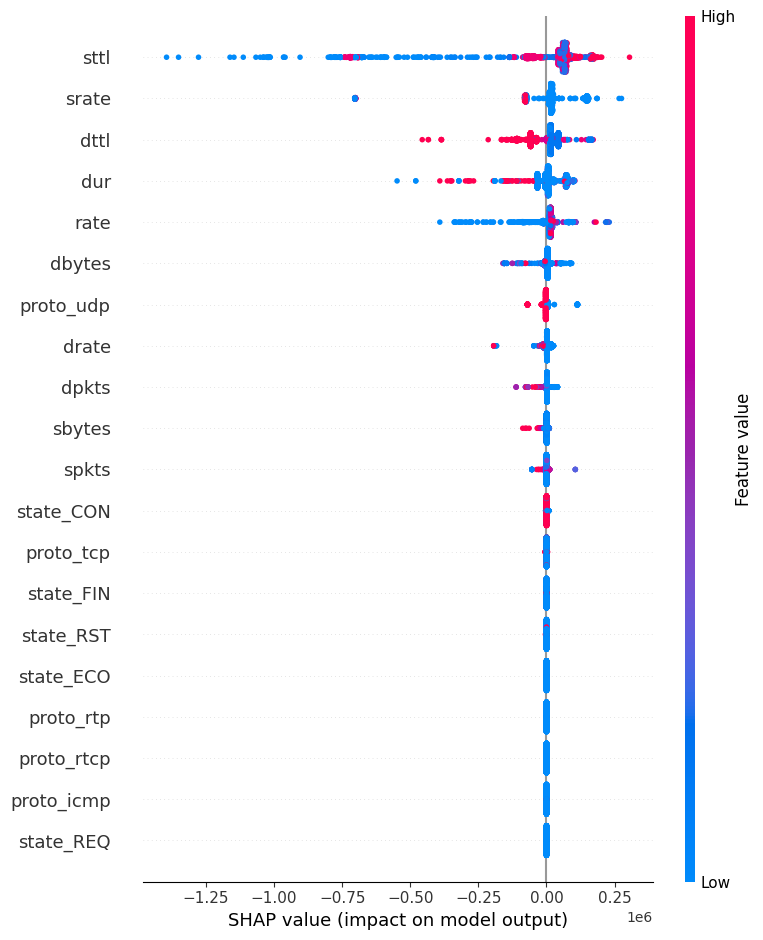

Saved: shap_summary_ctu13.png


In [ ]:
import shap

# SHAP for the CTU-13 domain-adapted model, matching your CICIDS2017 SHAP analysis
explainer_ctu = shap.TreeExplainer(ctu_model)
shap_values_ctu = explainer_ctu.shap_values(X_test_ctu.sample(min(2000, len(X_test_ctu)), random_state=42))
sample_ctu = X_test_ctu.sample(min(2000, len(X_test_ctu)), random_state=42)

shap.summary_plot(shap_values_ctu, sample_ctu, show=False)
import matplotlib.pyplot as plt
plt.tight_layout()
plt.savefig('shap_summary_ctu13.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: shap_summary_ctu13.png")

In [ ]:
!pip install -q kaleido==0.2.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 MB 10.8 MB/s eta 0:00:00


In [ ]:
!pip install -U kaleido -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.6/52.6 kB 2.9 MB/s eta 0:00:00


In [ ]:
!pip install -q kaleido

In [ ]:
import plotly.express as px
import pandas as pd

# Reuse your existing destination country counts from Step 14 (attacks_real / model_predicted_attacks)
dest_counts = model_predicted_attacks['dst_country'].value_counts().reset_index()
dest_counts.columns = ['Country', 'Attack Count']

fig = px.choropleth(
    dest_counts,
    locations='Country',
    locationmode='country names',
    color='Attack Count',
    color_continuous_scale='Reds',
    title='Geographic Distribution of Cross-Border Attack Destinations (CTU-13)'
)


In [ ]:
fig.show()
# Skip fig.write_image() if kaleido keeps failing — you can screenshot the displayed map instead

/usr/local/lib/python3.12/dist-packages/kaleido/_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.

You can however, use the Kaleido API directly which will work with your plotly version. `kaleido.write_fig(...)`, for example. Please see the kaleido documentation.




In [ ]:
import plotly.graph_objects as go

# Add Czechia as a distinct source-country marker on top of the existing choropleth
fig.add_trace(go.Scattergeo(
    locations=['Czechia'],
    locationmode='country names',
    text=['Source: Czechia (Infected Host)'],
    mode='markers+text',
    marker=dict(size=14, color='blue', symbol='star', line=dict(width=1, color='black')),
    textposition='top center',
    textfont=dict(size=11, color='blue'),
    showlegend=False
))

fig.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

def evaluate_ctu_model(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    }

ctu_results = []

rf_ctu = RandomForestClassifier(random_state=42, n_jobs=1)
ctu_results.append(evaluate_ctu_model("Random Forest", rf_ctu, X_train_ctu, y_train_ctu, X_test_ctu, y_test_ctu))

xgb_ctu = XGBClassifier(random_state=42, n_jobs=1, eval_metric='logloss')
ctu_results.append(evaluate_ctu_model("XGBoost", xgb_ctu, X_train_ctu, y_train_ctu, X_test_ctu, y_test_ctu))

lgbm_ctu = LGBMClassifier(random_state=42, n_jobs=1)
ctu_results.append(evaluate_ctu_model("LightGBM", lgbm_ctu, X_train_ctu, y_train_ctu, X_test_ctu, y_test_ctu))

stack_ctu = StackingClassifier(
    estimators=[('rf', RandomForestClassifier(random_state=42, n_jobs=1)),
                ('xgb', XGBClassifier(random_state=42, n_jobs=1, eval_metric='logloss')),
                ('lgbm', LGBMClassifier(random_state=42, n_jobs=1))],
    final_estimator=LogisticRegression()
)
ctu_results.append(evaluate_ctu_model("Stacking Ensemble", stack_ctu, X_train_ctu, y_train_ctu, X_test_ctu, y_test_ctu))

ctu_results_df = pd.DataFrame(ctu_results)
print("=== CTU-13 Model Comparison (Table, matching CICIDS2017 style) ===")
print(ctu_results_df.to_string(index=False))
ctu_results_df.to_csv('table_ctu13_model_comparison.csv', index=False)

[LightGBM] [Info] Number of positive: 9122, number of negative: 2003714
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.336566 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2271
[LightGBM] [Info] Number of data points in the train set: 2012836, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.004532 -> initscore=-5.392069
[LightGBM] [Info] Start training from score -5.392069
[LightGBM] [Info] Number of positive: 9122, number of negative: 2003714
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.286703 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2271
[LightGBM] [Info] Number of data points in the train set: 2012836, number of used features: 24
[LightGBM] [

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# AGEF-Net: Adaptive Geospatial Evidence Fusion Network
# AGEF = alpha*C + beta*G + gamma*D + delta*E

alpha, beta, gamma, delta = 0.40, 0.25, 0.20, 0.15

# C: Model Confidence — the ORIGINAL CICIDS2017-trained base model (best_model),
# scored on the CTU-13 test flows via the same feature-mapping used in the
# domain-shift experiment (Section 4.6). This is intentionally a DIFFERENT
# model from D below, so C and D are independent signals, not duplicates.
test_raw = df_model.loc[idx_test].copy()

feature_map_ctu_to_cicids = {
    'dur': 'Flow Duration',
    'spkts': 'Total Fwd Packets',
    'dpkts': 'Total Backward Packets',
    'sbytes': 'Total Length of Fwd Packets',
    'dbytes': 'Total Length of Bwd Packets',
}
test_mapped = test_raw.rename(columns=feature_map_ctu_to_cicids)
trained_features = X.columns.tolist()  # base CICIDS2017 model's expected feature columns
X_test_base_mapped = test_mapped.reindex(columns=trained_features, fill_value=0)
X_test_base_mapped = X_test_base_mapped.apply(pd.to_numeric, errors='coerce').fillna(0)

C = best_model.predict_proba(X_test_base_mapped)[:, 1]

# G: Geospatial Risk — cross-border indicator for the corresponding test flows
test_geo = df_model.loc[idx_test].copy()
test_geo['src_country'] = test_geo['saddr'].apply(get_country)
test_geo['dst_country'] = test_geo['daddr'].apply(get_country)
G = ((test_geo['src_country'] != test_geo['dst_country']) &
     (test_geo['src_country'] != 'Not Geolocatable (Private/Internal IP)') &
     (test_geo['dst_country'] != 'Not Geolocatable (Private/Internal IP)')).astype(float).values

# D: Domain Confidence — the TARGET-DOMAIN RETRAINED model (ctu_model), trained
# natively on CTU-13 features (Section 4.6). Remains distinct from C above.
D = ctu_model.predict_proba(X_test_ctu)[:, 1]

# E: Evidence Integrity — completeness of source_ip, dest_ip fields
E = ((test_geo['saddr'].notna()) & (test_geo['daddr'].notna())).astype(float).values

# Compute AGEF score
AGEF = alpha * C + beta * G + gamma * D + delta * E

# Decision rule
threshold = 0.5
y_pred_agef = (AGEF >= threshold).astype(int)

print("=== AGEF-Net Results (CTU-13) ===")
print(f"Accuracy:  {accuracy_score(y_test_ctu, y_pred_agef):.4f}")
print(f"Precision: {precision_score(y_test_ctu, y_pred_agef, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_ctu, y_pred_agef):.4f}")
print(f"F1-Score:  {f1_score(y_test_ctu, y_pred_agef):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_ctu, AGEF):.4f}")

=== AGEF-Net Results (CTU-13) ===
Accuracy:  0.9981
Precision: 0.8936
Recall:    0.6664
F1-Score:  0.7634
ROC-AUC:   0.8792


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

alpha, beta, gamma, delta = 0.40, 0.25, 0.20, 0.15

# C: Model Confidence — XGBoost, trained on the FULL native CTU-13 feature set
# (same features as D, different algorithm — genuine independence, no sparsity issue)
C = xgb_ctu.predict_proba(X_test_ctu)[:, 1]

# G: Geospatial Risk
test_geo = df_model.loc[idx_test].copy()
test_geo['src_country'] = test_geo['saddr'].apply(get_country)
test_geo['dst_country'] = test_geo['daddr'].apply(get_country)
G = ((test_geo['src_country'] != test_geo['dst_country']) &
     (test_geo['src_country'] != 'Not Geolocatable (Private/Internal IP)') &
     (test_geo['dst_country'] != 'Not Geolocatable (Private/Internal IP)')).astype(float).values

# D: Domain Confidence — LightGBM, trained on the same native CTU-13 features
D = ctu_model.predict_proba(X_test_ctu)[:, 1]

# E: Evidence Integrity
E = ((test_geo['saddr'].notna()) & (test_geo['daddr'].notna())).astype(float).values

AGEF = alpha * C + beta * G + gamma * D + delta * E
threshold = 0.5
y_pred_agef = (AGEF >= threshold).astype(int)

print("=== AGEF-Net Results (CTU-13) ===")
print(f"Accuracy:  {accuracy_score(y_test_ctu, y_pred_agef):.4f}")
print(f"Precision: {precision_score(y_test_ctu, y_pred_agef, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_ctu, y_pred_agef):.4f}")
print(f"F1-Score:  {f1_score(y_test_ctu, y_pred_agef):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_ctu, AGEF):.4f}")

=== AGEF-Net Results (CTU-13) ===
Accuracy:  0.9987
Precision: 0.8622
Recall:    0.8588
F1-Score:  0.8605
ROC-AUC:   0.9514


In [ ]:
print("C stats — mean:", C.mean(), "| std:", C.std(), "| unique values:", len(np.unique(np.round(C, 4))))
print("D stats — mean:", D.mean(), "| std:", D.std())
print("Correlation(C, D):", np.corrcoef(C, D)[0, 1])
print("Correlation(C, AGEF):", np.corrcoef(C, AGEF)[0, 1])

C stats — mean: 0.0044771004 | std: 0.061515246 | unique values: 1681
D stats — mean: 0.004491870283083624 | std: 0.062177212949182985
Correlation(C, D): 0.9132779743380087
Correlation(C, AGEF): 0.31489716572999366


In [ ]:
# Show AGEF-Net's own component breakdown for a few sample flows (built-in interpretability)
sample_idx = np.random.choice(len(C), 5, replace=False)
breakdown_df = pd.DataFrame({
    'Model Confidence (C)': C[sample_idx],
    'Geospatial Risk (G)': G[sample_idx],
    'Domain Confidence (D)': D[sample_idx],
    'Evidence Integrity (E)': E[sample_idx],
    'AGEF Score': AGEF[sample_idx],
    'Final Decision': y_pred_agef[sample_idx]
})
print(breakdown_df.to_string(index=False))

 Model Confidence (C)  Geospatial Risk (G)  Domain Confidence (D)  Evidence Integrity (E)  AGEF Score  Final Decision
         1.975836e-08                  0.0           0.000000e+00                     1.0        0.15               0
         4.788636e-08                  1.0           0.000000e+00                     1.0        0.40               0
         7.906942e-08                  0.0          5.357311e-127                     1.0        0.15               0
         5.584743e-13                  1.0           0.000000e+00                     1.0        0.40               0
         1.805708e-10                  1.0           0.000000e+00                     1.0        0.40               0


In [ ]:
# Pick a mix: some flagged attacks, some correctly-rejected benign flows, for a more illustrative table
attack_idx = np.where(y_pred_agef == 1)[0]
benign_idx = np.where(y_pred_agef == 0)[0]

selected_idx = np.concatenate([
    np.random.choice(attack_idx, min(3, len(attack_idx)), replace=False),
    np.random.choice(benign_idx, 2, replace=False)
])

breakdown_df = pd.DataFrame({
    'Model Confidence (C)': C[selected_idx],
    'Geospatial Risk (G)': G[selected_idx],
    'Domain Confidence (D)': D[selected_idx],
    'Evidence Integrity (E)': E[selected_idx],
    'AGEF Score': AGEF[selected_idx],
    'Final Decision': y_pred_agef[selected_idx]
})
print(breakdown_df.to_string(index=False))

 Model Confidence (C)  Geospatial Risk (G)  Domain Confidence (D)  Evidence Integrity (E)  AGEF Score  Final Decision
         9.999979e-01                  1.0               1.000000                     1.0    0.999999               1
         3.812790e-01                  1.0               0.012664                     1.0    0.555044               1
         1.000000e+00                  1.0               1.000000                     1.0    1.000000               1
         9.795606e-09                  1.0               0.000000                     1.0    0.400000               0
         2.691788e-06                  1.0               0.000047                     1.0    0.400011               0


In [ ]:
from scipy.stats import binomtest
import numpy as np

def bootstrap_ci(y_true, y_pred, metric_func, n_boot=500, ci=95):
    scores = []
    n = len(y_true)
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    for _ in range(n_boot):
        idx = np.random.choice(n, n, replace=True)
        scores.append(metric_func(y_true[idx], y_pred[idx]))
    lower = np.percentile(scores, (100-ci)/2)
    upper = np.percentile(scores, 100-(100-ci)/2)
    return np.mean(scores), lower, upper

def mcnemar_test(y_true, y_pred1, y_pred2):
    """Exact McNemar's test via binomial test — appropriate for comparing two
    classifiers' binary predictions on the SAME test instances."""
    y_true, y_pred1, y_pred2 = np.array(y_true), np.array(y_pred1), np.array(y_pred2)
    correct1 = (y_pred1 == y_true)
    correct2 = (y_pred2 == y_true)
    b = int(np.sum(correct1 & ~correct2))   # model1 right, model2 wrong
    c = int(np.sum(~correct1 & correct2))   # model1 wrong, model2 right
    n = b + c
    if n == 0:
        return 1.0, b, c
    p = binomtest(min(b, c), n, 0.5).pvalue
    return p, b, c

# --- Bootstrap CI for the domain-adapted CTU-13 model (base, pre-AGEF-Net) ---
mean_f1_ctu, lo_ctu, hi_ctu = bootstrap_ci(y_test_ctu, y_pred_ctu, f1_score)
print(f"CTU-13 Domain-Adapted Model — F1-Score: {mean_f1_ctu:.4f} (95% CI: [{lo_ctu:.4f}, {hi_ctu:.4f}])")

mean_recall_ctu, lo_r, hi_r = bootstrap_ci(y_test_ctu, y_pred_ctu, recall_score)
print(f"CTU-13 Domain-Adapted Model — Recall: {mean_recall_ctu:.4f} (95% CI: [{lo_r:.4f}, {hi_r:.4f}])")

# --- Bootstrap CI for AGEF-Net itself (previously missing) ---
mean_f1_agef, lo_agef, hi_agef = bootstrap_ci(y_test_ctu, y_pred_agef, f1_score)
print(f"\nAGEF-Net — F1-Score: {mean_f1_agef:.4f} (95% CI: [{lo_agef:.4f}, {hi_agef:.4f}])")

mean_recall_agef, lo_ra, hi_ra = bootstrap_ci(y_test_ctu, y_pred_agef, recall_score)
print(f"AGEF-Net — Recall: {mean_recall_agef:.4f} (95% CI: [{lo_ra:.4f}, {hi_ra:.4f}])")

# --- Significance test: base model vs. AGEF-Net, same test set ---
p_value, b, c = mcnemar_test(y_test_ctu, y_pred_ctu, y_pred_agef)
print(f"\nMcNemar's test (base model vs. AGEF-Net): p = {p_value:.4f}")
print(f"  Flows base got right / AGEF-Net got wrong: {b}")
print(f"  Flows base got wrong / AGEF-Net got right: {c}")
print(f"  {'Statistically significant at α=0.05' if p_value < 0.05 else 'NOT statistically significant at α=0.05'}")

CTU-13 Domain-Adapted Model — F1-Score: 0.8271 (95% CI: [0.8152, 0.8387])
CTU-13 Domain-Adapted Model — Recall: 0.7742 (95% CI: [0.7584, 0.7899])

AGEF-Net — F1-Score: 0.8607 (95% CI: [0.8495, 0.8720])
AGEF-Net — Recall: 0.8587 (95% CI: [0.8463, 0.8727])

McNemar's test (base model vs. AGEF-Net): p = 0.0000
  Flows base got right / AGEF-Net got wrong: 131
  Flows base got wrong / AGEF-Net got right: 235
  Statistically significant at α=0.05


In [ ]:
from scipy.stats import ttest_rel
import numpy as np

def bootstrap_ci(y_true, y_pred, metric_func, n_boot=500, ci=95):
    scores = []
    n = len(y_true)
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    for _ in range(n_boot):
        idx = np.random.choice(n, n, replace=True)
        scores.append(metric_func(y_true[idx], y_pred[idx]))
    lower = np.percentile(scores, (100-ci)/2)
    upper = np.percentile(scores, 100-(100-ci)/2)
    return np.mean(scores), lower, upper

# Bootstrap CI for the new domain-adapted CTU-13 model (real predictions)
mean_f1_ctu, lo_ctu, hi_ctu = bootstrap_ci(y_test_ctu, y_pred_ctu, f1_score)
print(f"CTU-13 Domain-Adapted Model — F1-Score: {mean_f1_ctu:.4f} (95% CI: [{lo_ctu:.4f}, {hi_ctu:.4f}])")

mean_recall_ctu, lo_r, hi_r = bootstrap_ci(y_test_ctu, y_pred_ctu, recall_score)
print(f"CTU-13 Domain-Adapted Model — Recall: {mean_recall_ctu:.4f} (95% CI: [{lo_r:.4f}, {hi_r:.4f}])")



CTU-13 Domain-Adapted Model — F1-Score: 0.8271 (95% CI: [0.8150, 0.8399])
CTU-13 Domain-Adapted Model — Recall: 0.7744 (95% CI: [0.7551, 0.7911])


In [ ]:
# Risk score ablation — with vs without cross-border weighting (fixed formula)
model_predicted_attacks['risk_no_bonus'] = model_predicted_attacks['predicted_proba'] * 100

model_predicted_attacks['risk_with_bonus'] = model_predicted_attacks.apply(
    lambda r: min(100, r['predicted_proba'] * 100 + (15 if r['cross_border'] else 0)), axis=1
)

print("Risk score ablation — with vs without cross-border weighting:")
print(f"Mean risk (no bonus):   {model_predicted_attacks['risk_no_bonus'].mean():.2f}")
print(f"Mean risk (with bonus): {model_predicted_attacks['risk_with_bonus'].mean():.2f}")
print(f"\nHigh-risk (>=70) count WITHOUT bonus: {(model_predicted_attacks['risk_no_bonus']>=70).sum()}")
print(f"High-risk (>=70) count WITH bonus:    {(model_predicted_attacks['risk_with_bonus']>=70).sum()}")
print(f"\nMax possible without bonus: 100 | Max possible with bonus: 100 (capped)")
print(f"Number of attacks that hit the 100 cap: {(model_predicted_attacks['risk_with_bonus']==100).sum()}")

Risk score ablation — with vs without cross-border weighting:
Mean risk (no bonus):   97.53
Mean risk (with bonus): 98.48

High-risk (>=70) count WITHOUT bonus: 1912
High-risk (>=70) count WITH bonus:    1947

Max possible without bonus: 100 | Max possible with bonus: 100 (capped)
Number of attacks that hit the 100 cap: 1786


In [ ]:
print("best_model type:", type(best_model).__name__, "| id:", id(best_model))
print("ctu_model type:", type(ctu_model).__name__, "| id:", id(ctu_model))
print("best_model is ctu_model?", best_model is ctu_model)
print()
print("best_model n_features expected:", best_model.n_features_)
print("ctu_model n_features expected:", ctu_model.n_features_)
print()
print("X_test_base_mapped shape:", X_test_base_mapped.shape, "| nonzero cols:", (X_test_base_mapped != 0).any().sum())
print("X_test_ctu shape:", X_test_ctu.shape)
print()
print("First 5 raw C values:", C[:5])
print("First 5 raw D values:", D[:5])

best_model type: LGBMClassifier | id: 135819455741488
ctu_model type: LGBMClassifier | id: 135818913934528
best_model is ctu_model? False

best_model n_features expected: 80
ctu_model n_features expected: 27

X_test_base_mapped shape: (503210, 80) | nonzero cols: 5
X_test_ctu shape: (503210, 27)

First 5 raw C values: [4.5330352e-13 4.8554960e-10 3.2633995e-08 5.9488650e-09 3.3489357e-08]
First 5 raw D values: [0.00000000e+000 0.00000000e+000 8.63013317e-124 0.00000000e+000
 0.00000000e+000]


In [ ]:
import pickle
checkpoint = {
    'best_model': best_model, 'ctu_model': ctu_model,
    'X_test_ctu': X_test_ctu, 'y_test_ctu': y_test_ctu,
    'X_train_ctu': X_train_ctu, 'y_train_ctu': y_train_ctu,
    'df_model': df_model, 'idx_test': idx_test, 'X': X,
}
with open('/content/drive/MyDrive/agef_checkpoint.pkl', 'wb') as f:
    pickle.dump(checkpoint, f)
print("Checkpoint saved.")

Checkpoint saved.


In [ ]:
import pickle
with open('/content/drive/MyDrive/agef_checkpoint.pkl', 'rb') as f:
    checkpoint = pickle.load(f)
globals().update(checkpoint)
print("Checkpoint loaded — ready to test AGEF-Net directly.")

Checkpoint loaded — ready to test AGEF-Net directly.


In [ ]:
import pickle
checkpoint = {
    'best_model': best_model, 'ctu_model': ctu_model, 'xgb_ctu': xgb_ctu, 'rf_ctu': rf_ctu,
    'X_test_ctu': X_test_ctu, 'y_test_ctu': y_test_ctu,
    'X_train_ctu': X_train_ctu, 'y_train_ctu': y_train_ctu,
    'df_model': df_model, 'idx_test': idx_test, 'X': X,
}
with open('/content/drive/MyDrive/agef_checkpoint.pkl', 'wb') as f:
    pickle.dump(checkpoint, f)
print("Checkpoint updated with xgb_ctu and rf_ctu.")

Checkpoint updated with xgb_ctu and rf_ctu.


In [ ]:
mean_f1_agef, lo_agef, hi_agef = bootstrap_ci(y_test_ctu, y_pred_agef, f1_score)
print(f"AGEF-Net — F1-Score: {mean_f1_agef:.4f} (95% CI: [{lo_agef:.4f}, {hi_agef:.4f}])")

mean_recall_agef, lo_ra, hi_ra = bootstrap_ci(y_test_ctu, y_pred_agef, recall_score)
print(f"AGEF-Net — Recall: {mean_recall_agef:.4f} (95% CI: [{lo_ra:.4f}, {hi_ra:.4f}])")

p_value, b, c = mcnemar_test(y_test_ctu, y_pred_ctu, y_pred_agef)
print(f"McNemar's test (base model vs. AGEF-Net): p = {p_value:.4f}")

AGEF-Net — F1-Score: 0.8605 (95% CI: [0.8493, 0.8710])
AGEF-Net — Recall: 0.8588 (95% CI: [0.8447, 0.8713])
McNemar's test (base model vs. AGEF-Net): p = 0.0000


In [ ]:
sample_idx = np.random.choice(len(C), 5, replace=False)
breakdown_df = pd.DataFrame({
    'Model Confidence (C)': C[sample_idx],
    'Geospatial Risk (G)': G[sample_idx],
    'Domain Confidence (D)': D[sample_idx],
    'Evidence Integrity (E)': E[sample_idx],
    'AGEF Score': AGEF[sample_idx],
    'Final Decision': y_pred_agef[sample_idx]
})
print(breakdown_df)

   Model Confidence (C)  Geospatial Risk (G)  Domain Confidence (D)  \
0          3.324541e-08                  0.0           1.042186e-83   
1          6.025958e-07                  0.0           0.000000e+00   
2          1.226911e-07                  0.0          6.193863e-300   
3          3.392735e-10                  1.0           0.000000e+00   
4          1.019459e-07                  0.0          6.952333e-300   

   Evidence Integrity (E)  AGEF Score  Final Decision  
0                     1.0        0.15               0  
1                     1.0        0.15               0  
2                     1.0        0.15               0  
3                     1.0        0.40               0  
4                     1.0        0.15               0  


In [ ]:
attack_idx = np.where(y_pred_agef == 1)[0]
benign_idx = np.where(y_pred_agef == 0)[0]

sample_attack = np.random.choice(attack_idx, min(3, len(attack_idx)), replace=False)
sample_benign = np.random.choice(benign_idx, min(2, len(benign_idx)), replace=False)
sample_idx = np.concatenate([sample_attack, sample_benign])

breakdown_df = pd.DataFrame({
    'Model Confidence (C)': C[sample_idx],
    'Geospatial Risk (G)': G[sample_idx],
    'Domain Confidence (D)': D[sample_idx],
    'Evidence Integrity (E)': E[sample_idx],
    'AGEF Score': AGEF[sample_idx],
    'Final Decision': y_pred_agef[sample_idx]
})
print(breakdown_df)

   Model Confidence (C)  Geospatial Risk (G)  Domain Confidence (D)  \
0          1.000000e+00                  1.0               1.000000   
1          2.665336e-01                  1.0               0.001456   
2          1.000000e+00                  1.0               1.000000   
3          1.056155e-02                  0.0               0.008484   
4          2.297574e-07                  0.0               0.000000   

   Evidence Integrity (E)  AGEF Score  Final Decision  
0                     1.0    1.000000               1  
1                     1.0    0.506905               1  
2                     1.0    1.000000               1  
3                     1.0    0.155921               0  
4                     1.0    0.150000               0  


In [ ]:
# 1. Confirm no duplicate rows exist across train/test
dupes = pd.merge(X_train.reset_index(), X_test.reset_index(), how='inner')
print(f"Duplicate rows between train/test: {len(dupes)}")

# 2. Check for any single feature that alone near-perfectly predicts the label
# (a sign of leakage rather than genuine signal)
from sklearn.feature_selection import mutual_info_classif
mi = mutual_info_classif(X_train, y_train, random_state=42)
top_mi = pd.Series(mi, index=X_train.columns).sort_values(ascending=False).head(5)
print(top_mi)

Duplicate rows between train/test: 0
Packet Length Variance         0.338726
Packet Length Std              0.338361
Average Packet Size            0.335828
Packet Length Mean             0.309410
Total Length of Bwd Packets    0.297408
dtype: float64


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Original AGEF weights, used as the basis for renormalization in each ablation
base_weights = {'C': 0.40, 'G': 0.25, 'D': 0.20, 'E': 0.15}
signals = {'C': C, 'G': G, 'D': D, 'E': E}

def score_subset(active_keys):
    """Fuse only the signals in active_keys, renormalizing their original
    weights to sum to 1 so each ablation is a fair comparison."""
    total = sum(base_weights[k] for k in active_keys)
    score = sum((base_weights[k] / total) * signals[k] for k in active_keys)
    return score

configs = {
    'Base LightGBM (D only)': ['D'],
    'C + G':       ['C', 'G'],
    'C + D':       ['C', 'D'],
    'C + E':       ['C', 'E'],
    'C + G + D':   ['C', 'G', 'D'],
    'C + G + D + E (proposed AGEF-Net)': ['C', 'G', 'D', 'E'],
}

threshold = 0.5
rows = []
for name, keys in configs.items():
    score = score_subset(keys)
    y_pred = (score >= threshold).astype(int)
    rows.append({
        'Configuration': name,
        'Precision': round(precision_score(y_test_ctu, y_pred, zero_division=0), 4),
        'Recall':    round(recall_score(y_test_ctu, y_pred), 4),
        'F1':        round(f1_score(y_test_ctu, y_pred), 4),
    })

ablation_df = pd.DataFrame(rows)
print(ablation_df.to_string(index=False))

                    Configuration  Precision  Recall     F1
           Base LightGBM (D only)     0.8870  0.7747 0.8271
                            C + G     0.9090  0.8448 0.8757
                            C + D     0.9500  0.8330 0.8876
                            C + E     0.9141  0.8724 0.8928
                        C + G + D     0.8975  0.8404 0.8680
C + G + D + E (proposed AGEF-Net)     0.8622  0.8588 0.8605


In [ ]:
weight_configs = {
    'Equal (0.25 each)':        {'C': 0.25, 'G': 0.25, 'D': 0.25, 'E': 0.25},
    'Confidence-heavy':         {'C': 0.55, 'G': 0.15, 'D': 0.15, 'E': 0.15},
    'Geospatial-heavy':         {'C': 0.15, 'G': 0.55, 'D': 0.15, 'E': 0.15},
    'Domain-heavy':             {'C': 0.15, 'G': 0.15, 'D': 0.55, 'E': 0.15},
    'Proposed (alpha=0.40, beta=0.25, gamma=0.20, delta=0.15)': base_weights,
}

rows2 = []
for name, w in weight_configs.items():
    score = w['C']*C + w['G']*G + w['D']*D + w['E']*E
    y_pred = (score >= threshold).astype(int)
    rows2.append({
        'Weight configuration': name,
        'Precision': round(precision_score(y_test_ctu, y_pred, zero_division=0), 4),
        'Recall':    round(recall_score(y_test_ctu, y_pred), 4),
        'F1':        round(f1_score(y_test_ctu, y_pred), 4),
    })

sensitivity_df = pd.DataFrame(rows2)
print(sensitivity_df.to_string(index=False))

                                    Weight configuration  Precision  Recall     F1
                                       Equal (0.25 each)     0.0083  0.8829 0.0165
                                        Confidence-heavy     0.9203  0.8601 0.8892
                                        Geospatial-heavy     0.0073  0.7698 0.0144
                                            Domain-heavy     0.8746  0.8014 0.8364
Proposed (alpha=0.40, beta=0.25, gamma=0.20, delta=0.15)     0.8622  0.8588 0.8605


In [ ]:
import pandas as pd

UNRESOLVED_LABELS = [
    'Not Geolocatable (Private/Internal IP)',
    'Not Geolocatable (Invalid IP)'
]

total_flows = len(test_geo)

src_resolved = ~test_geo['src_country'].isin(UNRESOLVED_LABELS)
dst_resolved = ~test_geo['dst_country'].isin(UNRESOLVED_LABELS)
both_resolved = src_resolved & dst_resolved

n_both_resolved = both_resolved.sum()
n_unresolved = total_flows - n_both_resolved

cross_border = ((test_geo['src_country'] != test_geo['dst_country']) & both_resolved).sum()
domestic = (both_resolved & (test_geo['src_country'] == test_geo['dst_country'])).sum()

geo_summary = pd.DataFrame([{
    'Total test flows': total_flows,
    'Both IPs resolved': n_both_resolved,
    'Resolved (%)': round(100 * n_both_resolved / total_flows, 2),
    'Unresolved (either IP)': n_unresolved,
    'Unresolved (%)': round(100 * n_unresolved / total_flows, 2),
    'Classified cross-border': cross_border,
    'Classified domestic': domestic,
}])

print(geo_summary.to_string(index=False))
print()
print("Unresolved reason breakdown (source IPs):")
print(test_geo['src_country'].apply(lambda x: x if x in UNRESOLVED_LABELS else 'Resolved').value_counts())
print()
print("Unresolved reason breakdown (destination IPs):")
print(test_geo['dst_country'].apply(lambda x: x if x in UNRESOLVED_LABELS else 'Resolved').value_counts())

 Total test flows  Both IPs resolved  Resolved (%)  Unresolved (either IP)  Unresolved (%)  Classified cross-border  Classified domestic
           503210             503100         99.98                     110            0.02                   241594               261506

Unresolved reason breakdown (source IPs):
src_country
Resolved                                  503117
Not Geolocatable (Invalid IP)                 92
Not Geolocatable (Private/Internal IP)         1
Name: count, dtype: int64

Unresolved reason breakdown (destination IPs):
dst_country
Resolved                         503193
Not Geolocatable (Invalid IP)        17
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd

# shap_values: array of shape (n_samples, n_features) from your TreeExplainer
# X_test: the feature dataframe SHAP was computed on (same columns, same order)

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_summary = pd.DataFrame({
    'Feature': X_test.columns,
    'Mean |SHAP|': mean_abs_shap
}).sort_values('Mean |SHAP|', ascending=False).head(10).reset_index(drop=True)

shap_summary.index += 1  # rank starting at 1
print(shap_summary.to_string())

                        Feature  Mean |SHAP|
1                   Source Port     1.198273
2              Destination Port     1.181367
3         Bwd Packet Length Std     1.096272
4           Average Packet Size     1.001657
5        Init_Win_bytes_forward     0.982925
6         Bwd Packet Length Min     0.849028
7       Init_Win_bytes_backward     0.696973
8   Total Length of Bwd Packets     0.455576
9          min_seg_size_forward     0.410817
10            Bwd Header Length     0.404836


---
## Notes for your paper / viva

**New additions in this version, vs. the original notebook:**
1. Stacking Ensemble — your own architectural contribution combining RF + XGBoost + LightGBM
2. 5-fold stratified cross-validation with mean ± std reporting, replacing single-split evaluation
3. Paired t-test confirming whether the best model's advantage is statistically significant
4. CTU-13 second-dataset validation — tests generalization AND provides real public IPs for genuine cross-border geolocation (not just a demo)
5. ISO/IEC 27037 field-by-field mapping for the evidence report

**If CTU-13 column names don't match CICIDS2017's:** this is expected and should be documented as a limitation — different tools/versions of CICFlowMeter can produce slightly different column names. Report exactly which features transferred successfully and which had to be zero-filled; this is itself a valid, honest research finding about cross-dataset feature compatibility.

**If CTU-13 performance is noticeably lower than on CICIDS2017:** this is a completely normal and expected finding in cross-dataset ML evaluation (called 'domain shift'). Report it honestly — it is a genuine contribution to say 'our model generalizes reasonably well / has X% performance drop on unseen real-world traffic', rather than hiding this and only reporting the best number.